# Parte 2 — Entrenamiento y comparación de modelos

Tecnicatura Universitaria en Inteligencia Artificial (FCEIA - UNR) · Computer Vision

Comparamos dos enfoques para generar **embeddings faciales** sobre el mismo test y con las mismas métricas:

| | Modelo A — CNN custom | Modelo B — ArcFace preentrenado |
|---|---|---|
| Qué es | ResNet chica diseñada y entrenada por nosotros desde cero sobre Pins (75 identidades) | `w600k_r50.onnx` de InsightFace (`buffalo_l`) usado como extractor, sin reentrenar |
| Objetivo | Ver qué se logra con un modelo propio y pocos datos | Línea de base fuerte |

Usa los rostros alineados y los splits que generó `1-pre-processing.ipynb` (`data/processed/aligned`, `data/splits`).

## Equipo
- Facundo Quinteros - Q-0493/6 - @FacuQuinteros03
- Roberto Lasarte - L-3370/7 - @RoberLasarte332

## Índice
0. Configuración y datos
1. Modelo A — CNN custom (arquitectura, entrenamiento, experimentos, exportación)
2. Modelo B — ArcFace preentrenado
3. Evaluación
   a) Verificación · b) Identificación · c) Umbral · d) Clustering · e) Análisis de errores · f) Costo computacional ·
   g) Sesgos de la evaluación y prueba con fotos propias
4. Comparación y elección final
5. Exportación del modelo

## 0. Configuración y datos

In [1]:
import copy
import json
import random
import sys
import time
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

import onnxruntime as ort  # después de torch: así toma las librerías CUDA que trae torch

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from lib import face_pipeline as fp
from lib.augmentation import build_train_augmentation
from lib.custom_cnn import EmbeddingExport, FaceCNN, MarginHead, SoftmaxHead, count_parameters

SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Precisión mixta desactivada: en la GTX 1650 (serie GTX 16xx) las convoluciones en fp16 devuelven NaN incluso con
# el modelo sin entrenar (lo verificamos). En fp32 funciona bien y el modelo entra en los 4 GB.
AMP = False
torch.backends.cudnn.benchmark = True
SPLITS_DIR = ROOT / "data" / "splits"
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "data" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
META = json.loads((SPLITS_DIR / "meta.json").read_text(encoding="utf-8"))
FACE_SIZE = META["face_size"]

ort.set_default_logger_severity(3)
PROVIDERS = [p for p in ("CUDAExecutionProvider", "CPUExecutionProvider") if p in ort.get_available_providers()]
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=UserWarning)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("onnxruntime:", PROVIDERS)

/root/venvs/tp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-28 00:27:48.190089858 [W:onnxruntime:Default, device_discovery.cc:325 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:92 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


device: cuda NVIDIA GeForce GTX 1650
onnxruntime: ['CUDAExecutionProvider', 'CPUExecutionProvider']


In [2]:
SPLITS = ["train", "val_closed", "test_closed", "val_open", "test_open"]
splits = {s: pd.read_csv(SPLITS_DIR / f"{s}.csv") for s in SPLITS}
display(pd.DataFrame({s: {"identidades": d.identity.nunique(), "imágenes": len(d)} for s, d in splits.items()}).T)


def load_faces(paths):
    return np.stack([cv2.imread(str(ROOT / p)) for p in paths])


t0 = time.perf_counter()
faces = {s: load_faces(d.aligned_path) for s, d in splits.items()}
print(f"Rostros alineados en memoria: {sum(len(v) for v in faces.values())} ({time.perf_counter() - t0:.0f} s)")
N_CLASSES = splits["train"].label.nunique()

,identidades,imágenes
train,75,9138
val_closed,75,1142
test_closed,75,1143
val_open,10,1774
test_open,20,3054


Rostros alineados en memoria: 16251 (77 s)


### Preprocesamiento idéntico en entrenamiento e inferencia

El `Dataset` de PyTorch convierte cada rostro con la misma regla que `fp.to_model_input` (la que usa la app):
BGR→RGB, `(x − 127.5) / 127.5`, HWC→CHW. Lo verificamos numéricamente antes de entrenar, porque una diferencia acá
es la causa número uno de que "el modelo anda en la notebook pero no en la app".

In [3]:
def to_tensor(face_bgr):
    rgb = np.ascontiguousarray(face_bgr[:, :, ::-1])
    return torch.from_numpy(rgb).permute(2, 0, 1).float().sub(127.5).div(127.5)


class FaceDataset(Dataset):
    def __init__(self, images, labels, augment=None):
        self.images, self.labels, self.augment = images, labels, augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = self.images[i]
        if self.augment is not None:
            img = self.augment(image=img)["image"]
        return to_tensor(img), int(self.labels[i])


sample = faces["val_open"][:8]
diff = np.abs(torch.stack([to_tensor(f) for f in sample]).numpy() - fp.to_model_input(list(sample))).max()
print(f"Máxima diferencia entre el Dataset de entrenamiento y fp.to_model_input (app): {diff:.2e}")
assert diff < 1e-5

Máxima diferencia entre el Dataset de entrenamiento y fp.to_model_input (app): 5.96e-08


## 1. Modelo A — CNN custom

### 1.1 Enfoque

El objetivo no es clasificar las 75 identidades de entrenamiento sino producir un **embedding** donde las fotos de una
misma persona queden cerca y las de personas distintas lejos, **también para personas que no vio**. Entrenamos con una
tarea de clasificación sobre las 75 identidades y usamos la capa previa al clasificador (normalizada L2) como
embedding. Probamos dos cabezas:

- **Softmax** (lineal + cross-entropy): lo más simple. Separa clases, pero no obliga a que queden compactas en ángulo.
- **Margen angular** (CosFace / ArcFace): normaliza embedding y pesos y exige un margen `m` en el ángulo con la clase
  correcta. Produce clusters compactos en la esfera, que es justo lo que mide la similitud coseno de la app.

### 1.2 Arquitectura (`src/lib/custom_cnn.py`)

ResNet chica para entradas de 112×112:

| Bloque | Salida | Detalle |
|---|---|---|
| Stem | 32×56×56 | conv 3×3 stride 2 + BN + PReLU |
| Etapa 1 | 32×56×56 | 2 bloques residuales |
| Etapa 2 | 64×28×28 | 2 bloques residuales (el primero con stride 2) |
| Etapa 3 | 128×14×14 | 2 bloques residuales |
| Etapa 4 | 256×7×7 | 2 bloques residuales |
| Pooling | 256 | **GDC** (conv depthwise 7×7) o **GAP** (promedio global) |
| Cabeza | 512 | Dropout + lineal + BN1d → embedding |

Decisiones:
- **Tamaño (~2,9 M de parámetros)**: la primera versión tenía el doble de canales (64→512, 11,4 M de parámetros) y
  tardaba 55 s por época en la GTX 1650. Con 9.000 imágenes de entrenamiento, una red de ese tamaño además tiene más
  riesgo de memorizar. Bajar a la mitad de canales reduce el cálculo ~4 veces y nos permite correr los 5 experimentos.
- **Bloques residuales**: permiten 16 capas convolucionales sin problemas de gradiente; con pocos datos, una red más
  profunda sin atajos entrena peor.
- **BatchNorm** en todas las convoluciones: estabiliza y acelera el entrenamiento y regulariza un poco.
- **PReLU** en vez de ReLU: es la elección estándar en reconocimiento facial (ArcFace, MobileFaceNet); evita neuronas
  "muertas" con un costo mínimo.
- **Pooling**: como las caras están alineadas, cada zona (ojos, nariz, boca) cae siempre en la misma posición del mapa
  7×7. El **GAP** la promedia y pierde esa información; el **GDC** aprende un peso por posición y canal. Lo comparamos.
- **Dropout** antes de la capa del embedding: con ~120 fotos por persona, el sobreajuste es el riesgo principal.
- **Embedding de 512**, igual que ArcFace, para comparar en las mismas condiciones y no cambiar `EMBEDDING_DIM`.

In [4]:
model = FaceCNN(pooling="gdc")
x = torch.zeros(2, 3, FACE_SIZE, FACE_SIZE)
shapes = []
h = model.stem(x)
shapes.append(("stem", tuple(h.shape[1:])))
for i, blk in enumerate(model.body):
    h = blk(h)
    shapes.append((f"bloque {i + 1}", tuple(h.shape[1:])))
h = model.pool(h)
shapes.append(("pooling (GDC)", tuple(h.shape[1:])))
shapes.append(("embedding", tuple(model.head(h).shape[1:])))
display(pd.DataFrame(shapes, columns=["capa", "salida (C, H, W)"]).set_index("capa").T)
print(f"Parámetros: GDC {count_parameters(FaceCNN(pooling='gdc')) / 1e6:.2f} M · GAP {count_parameters(FaceCNN(pooling='gap')) / 1e6:.2f} M")

capa,stem,bloque 1,bloque 2,bloque 3,bloque 4,bloque 5,bloque 6,bloque 7,bloque 8,pooling (GDC),embedding
"salida (C, H, W)","(32, 56, 56)","(32, 56, 56)","(32, 56, 56)","(64, 28, 28)","(64, 28, 28)","(128, 14, 14)","(128, 14, 14)","(256, 7, 7)","(256, 7, 7)","(256, 1, 1)","(512,)"


Parámetros: GDC 2.94 M · GAP 2.93 M


### 1.3 Entrenamiento

- **Optimizador**: AdamW (lr 2e-3, weight decay 5e-4), con *warmup* lineal de 2 épocas y decaimiento coseno.
- **Batch** 128, hasta 15 épocas, en fp32 (la GTX 1650 da NaN en fp16, ver la configuración).
- **Augmentation** solo en train (`build_train_augmentation`, sección 6 de la notebook 1).
- En cada época medimos: loss y accuracy de train y `val_closed` (mismas personas, otras fotos) y **AUC y EER de
  verificación en `val_open`** (10 personas que el modelo nunca ve). Como lo que nos importa es el embedding para
  gente nueva, el **mejor checkpoint y el early stopping se deciden por el AUC en `val_open`**, no por
  la accuracy de clasificación. Paciencia: 4 épocas.

In [5]:
from sklearn.metrics import roc_auc_score, roc_curve


def embed_torch(backbone, images, batch_size=256):
    backbone.eval()
    out = []
    with torch.no_grad(), torch.autocast(DEVICE.type, enabled=AMP):
        for i in range(0, len(images), batch_size):
            xb = torch.stack([to_tensor(f) for f in images[i : i + batch_size]]).to(DEVICE)
            out.append(F.normalize(backbone(xb).float()).cpu().numpy())
    return np.concatenate(out)


def pair_scores(emb, ids):
    """Similitud coseno de todos los pares (i < j) y si son la misma persona."""
    S = emb @ emb.T
    iu = np.triu_indices(len(ids), 1)
    return S[iu], (ids[:, None] == ids[None, :])[iu]


def eer(y_true, scores):
    fpr, tpr, thr = roc_curve(y_true, scores)
    i = np.nanargmin(np.abs(fpr - (1 - tpr)))
    return (fpr[i] + 1 - tpr[i]) / 2, thr[i]


VAL_OPEN_IDS = splits["val_open"].identity.to_numpy()


def val_open_metrics(backbone):
    s, same = pair_scores(embed_torch(backbone, faces["val_open"]), VAL_OPEN_IDS)
    return roc_auc_score(same, s), eer(same, s)[0]


def train_model(name, pooling="gdc", head="softmax", augment=True, epochs=15, lr=2e-3, wd=5e-4, batch_size=128,
                dropout=0.2, margin=0.35, scale=30.0, patience=4):
    seed_everything()
    backbone = FaceCNN(pooling=pooling, dropout=dropout).to(DEVICE)
    clf = (SoftmaxHead(512, N_CLASSES) if head == "softmax" else MarginHead(512, N_CLASSES, head, scale, margin)).to(DEVICE)
    params = list(backbone.parameters()) + list(clf.parameters())
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    aug = build_train_augmentation(FACE_SIZE) if augment else None
    if aug is not None:
        aug.set_random_seed(SEED)
    train_dl = DataLoader(FaceDataset(faces["train"], splits["train"].label.to_numpy(), aug), batch_size=batch_size,
                          shuffle=True, num_workers=4, drop_last=True, persistent_workers=True,
                          worker_init_fn=lambda w: np.random.seed(SEED + w))
    val_dl = DataLoader(FaceDataset(faces["val_closed"], splits["val_closed"].label.to_numpy()), batch_size=256)
    steps = epochs * len(train_dl)
    warm = 2 * len(train_dl)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, steps - warm)))
    )
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best, best_auc, bad = [], None, -1, 0
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        backbone.train()
        clf.train()
        tl, tc, tn = 0.0, 0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE.type, enabled=AMP):
                emb = backbone(xb)
                logits = clf(emb.float(), yb)
                loss = F.cross_entropy(logits, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            with torch.no_grad():
                pred = clf(emb.float()).argmax(1)
            tl += loss.item() * len(yb)
            tc += (pred == yb).sum().item()
            tn += len(yb)
        backbone.eval()
        clf.eval()
        vl, vc, vn = 0.0, 0, 0
        with torch.no_grad(), torch.autocast(DEVICE.type, enabled=AMP):
            for xb, yb in val_dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                emb = backbone(xb).float()
                vl += F.cross_entropy(clf(emb, yb), yb).item() * len(yb)
                vc += (clf(emb).argmax(1) == yb).sum().item()
                vn += len(yb)
        auc, e = val_open_metrics(backbone)
        hist.append({"epoch": ep, "train_loss": tl / tn, "train_acc": tc / tn, "val_loss": vl / vn,
                     "val_acc": vc / vn, "val_open_auc": auc, "val_open_eer": e})
        if auc > best_auc:
            best_auc, bad = auc, 0
            best = {"epoch": ep, "backbone": copy.deepcopy(backbone.state_dict()), "head": copy.deepcopy(clf.state_dict())}
        else:
            bad += 1
        if bad >= patience:
            break
    backbone.load_state_dict(best["backbone"])
    clf.load_state_dict(best["head"])
    hist = pd.DataFrame(hist)
    b = hist.loc[best["epoch"] - 1]
    summary = {"experimento": name, "pooling": pooling, "cabeza": head, "augmentation": augment,
               "épocas": len(hist), "mejor época": best["epoch"], "train acc": b.train_acc,
               "val_closed acc": b.val_acc, "val_open AUC": b.val_open_auc, "val_open EER": b.val_open_eer,
               "minutos": (time.perf_counter() - t0) / 60}
    print(f"{name}: mejor época {best['epoch']}/{len(hist)} · val_open AUC {b.val_open_auc:.4f} · "
          f"EER {b.val_open_eer:.4f} · {summary['minutos']:.1f} min")
    return backbone, clf, hist, summary

### 1.4 Experimentos

Cambiamos **una cosa por vez** para poder atribuir cada mejora:

| # | Cambio respecto del anterior | Pregunta |
|---|---|---|
| E1 | Softmax, GAP, **sin augmentation** | Línea de base: ¿cuánto sobreajusta? |
| E2 | + augmentation | ¿Reduce el sobreajuste y mejora el embedding? |
| E3 | GAP → **GDC** | ¿Aprovechar que las caras están alineadas ayuda? |
| E4 | Softmax → **CosFace** (s=30, m=0.35) | ¿Un margen angular da mejores embeddings para gente nueva? |
| E5 | CosFace → **ArcFace** (s=30, m=0.35) | ¿Margen aditivo en el ángulo vs. en el coseno? |

In [6]:
EXPERIMENTS = [
    ("E1 softmax · GAP · sin aug", dict(pooling="gap", head="softmax", augment=False)),
    ("E2 softmax · GAP · aug", dict(pooling="gap", head="softmax", augment=True)),
    ("E3 softmax · GDC · aug", dict(pooling="gdc", head="softmax", augment=True)),
    ("E4 CosFace · GDC · aug", dict(pooling="gdc", head="cosface", augment=True)),
    ("E5 ArcFace · GDC · aug", dict(pooling="gdc", head="arcface", augment=True)),
]
RUNS_DIR = RESULTS_DIR / "runs"
RUNS_DIR.mkdir(exist_ok=True)


def run_or_load(name, cfg):
    """Entrena y guarda el mejor checkpoint; si ya existe, lo carga (re-ejecutar la notebook no reentrena)."""
    path = RUNS_DIR / f"{name.split()[0]}.pt"
    if path.exists():
        ck = torch.load(path, weights_only=False)
        backbone = FaceCNN(pooling=cfg["pooling"]).to(DEVICE)
        backbone.load_state_dict(ck["backbone"])
        head = (SoftmaxHead(512, N_CLASSES) if cfg["head"] == "softmax" else MarginHead(512, N_CLASSES, cfg["head"])).to(DEVICE)
        head.load_state_dict(ck["head"])
        s = ck["summary"]
        print(f"{name}: cargado de {path.relative_to(ROOT)} · mejor época {s['mejor época']}/{s['épocas']} · "
              f"val_open AUC {s['val_open AUC']:.4f} · entrenamiento original {s['minutos']:.1f} min")
        return backbone, head, ck["hist"], s
    backbone, head, hist, summary = train_model(name, **cfg)
    torch.save({"backbone": backbone.state_dict(), "head": head.state_dict(), "hist": hist, "summary": summary}, path)
    return backbone, head, hist, summary


runs = {name: run_or_load(name, cfg) for name, cfg in EXPERIMENTS}
exp_table = pd.DataFrame([r[3] for r in runs.values()]).set_index("experimento")
exp_table.to_csv(RESULTS_DIR / "experiments.csv")
display(exp_table)

E1 softmax · GAP · sin aug: mejor época 6/10 · val_open AUC 0.8405 · EER 0.2409 · 3.6 min


E2 softmax · GAP · aug: mejor época 13/15 · val_open AUC 0.8559 · EER 0.2296 · 5.0 min


E3 softmax · GDC · aug: mejor época 12/15 · val_open AUC 0.8679 · EER 0.2184 · 5.0 min


E4 CosFace · GDC · aug: mejor época 14/15 · val_open AUC 0.8628 · EER 0.2212 · 5.2 min


E5 ArcFace · GDC · aug: mejor época 14/15 · val_open AUC 0.8700 · EER 0.2148 · 5.2 min


,pooling,cabeza,augmentation,épocas,mejor época,train acc,val_closed acc,val_open AUC,val_open EER,minutos
experimento,,,,,,,,,,
E1 softmax · GAP · sin aug,gap,softmax,False,10,6,0.7948,0.5350,0.8405,0.2409,3.6153
E2 softmax · GAP · aug,gap,softmax,True,15,13,0.7667,0.8030,0.8559,0.2296,4.9914
E3 softmax · GDC · aug,gdc,softmax,True,15,12,0.8861,0.8853,0.8679,0.2184,5.0415
E4 CosFace · GDC · aug,gdc,cosface,True,15,14,0.9254,0.9387,0.8628,0.2212,5.1709
E5 ArcFace · GDC · aug,gdc,arcface,True,15,14,0.9223,0.9291,0.8700,0.2148,5.2098


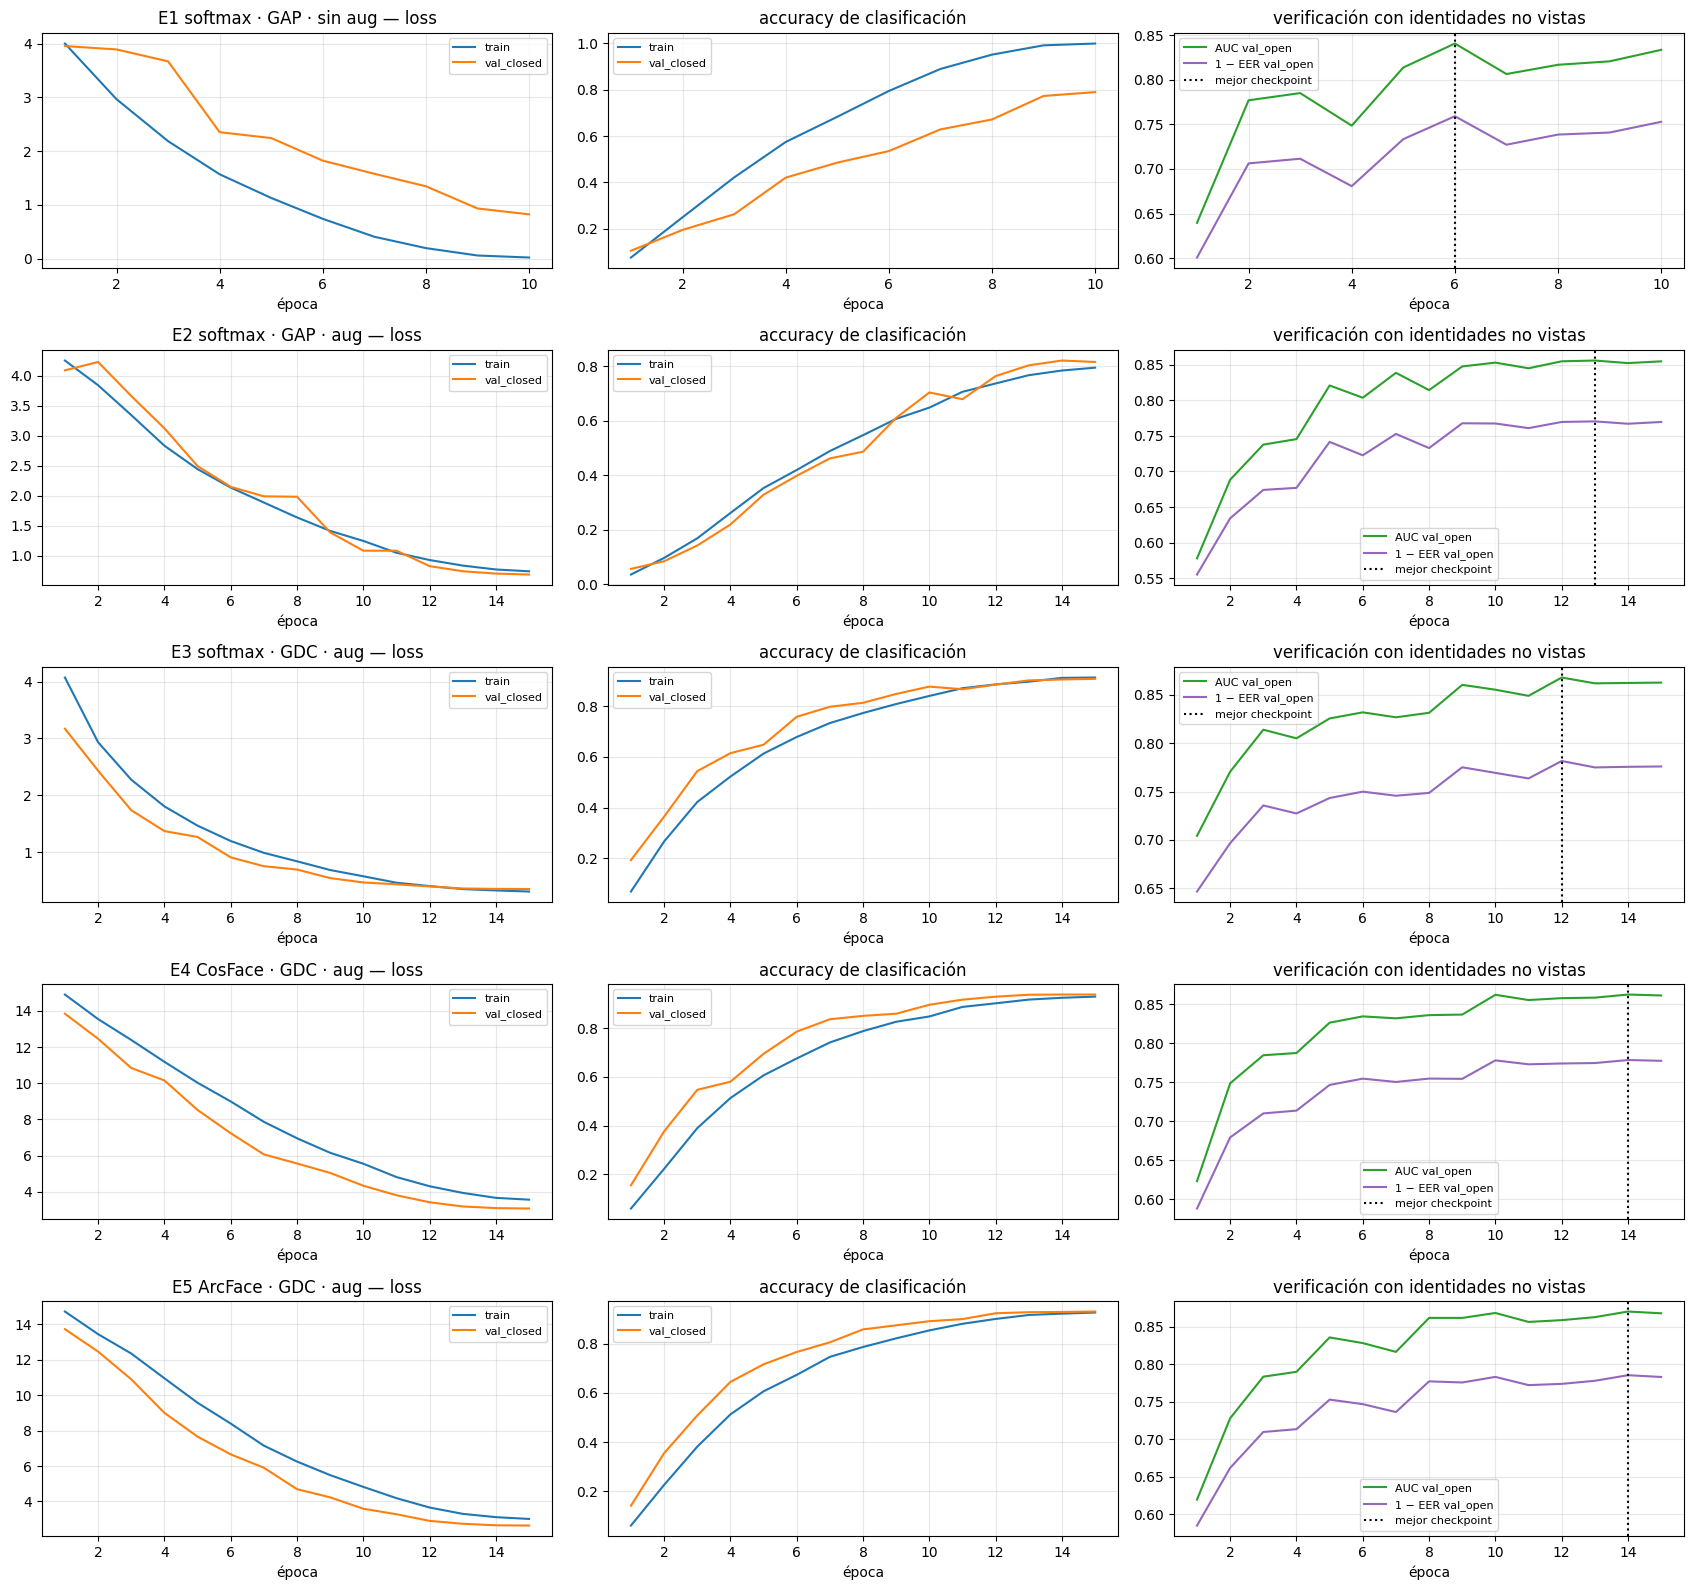

In [7]:
fig, axes = plt.subplots(len(runs), 3, figsize=(17, 3.2 * len(runs)), squeeze=False)
for row, (name, (_, _, hist, summ)) in zip(axes, runs.items()):
    row[0].plot(hist.epoch, hist.train_loss, label="train")
    row[0].plot(hist.epoch, hist.val_loss, label="val_closed")
    row[0].set_title(f"{name} — loss")
    row[1].plot(hist.epoch, hist.train_acc, label="train")
    row[1].plot(hist.epoch, hist.val_acc, label="val_closed")
    row[1].set_title("accuracy de clasificación")
    row[2].plot(hist.epoch, hist.val_open_auc, color="tab:green", label="AUC val_open")
    row[2].plot(hist.epoch, 1 - hist.val_open_eer, color="tab:purple", label="1 − EER val_open")
    row[2].axvline(summ["mejor época"], color="k", ls=":", label="mejor checkpoint")
    row[2].set_title("verificación con identidades no vistas")
    for ax in row:
        ax.set_xlabel("época")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretación de los experimentos.**

- **E1 (sin augmentation) sobreajusta**: el accuracy de train llega a ~100% mientras que `val_closed` se queda en ~79%, y
  la loss de validación deja de bajar al mismo ritmo que la de train. El AUC en `val_open` toca su máximo en la época 6 y
  después oscila: el modelo memoriza las fotos de entrenamiento en vez de aprender rasgos generales. El early stopping
  lo corta en la época 10.
- **E2 (+ augmentation)**: las curvas de train y validación quedan juntas (el sobreajuste desaparece) y el AUC con
  personas no vistas sube de 0.841 a **0.856**. La augmentation es la mejora más clara.
- **E3 (GAP → GDC)**: AUC **0.868** y accuracy de `val_closed` 89% (vs. 80%). Confirma la hipótesis: como las caras
  están alineadas, conservar *dónde* está cada rasgo (GDC) ayuda más que promediarlo (GAP).
- **E4 / E5 (margen angular)**: la mejor accuracy de clasificación (~93–94% en `val_closed`) y E5 (ArcFace) el mejor AUC
  en `val_open` (**0.870**), aunque la diferencia con E3 es chica. Ambos tuvieron su mejor época en la 14 de 15: **seguían
  mejorando cuando se cortó el entrenamiento**. Las pérdidas con margen convergen más lento, y con más épocas
  probablemente la ventaja sobre softmax sería mayor.
- En E2–E5 el accuracy de validación queda **por encima** del de train: es esperable, porque en train el modelo ve
  imágenes con augmentation y dropout (más difíciles) y en validación las ve limpias.

**Qué no funcionó:** la primera versión de la red tenía el doble de canales (11,4 M de parámetros) y tardaba 55 s por
época; la precisión mixta (fp16) devolvía `NaN` en la GTX 1650. Las dos cosas se resolvieron achicando la red y
entrenando en fp32. **Elegimos E5 como Modelo A.**

### 1.5 Modelo A final: accuracy closed-set y exportación a ONNX

Elegimos el experimento con mejor AUC en `val_open` (nunca miramos el test para elegir). Reportamos su accuracy de
clasificación en `test_closed` y lo exportamos a ONNX con un envoltorio que devuelve el embedding **ya normalizado**.
ONNX es la opción recomendada: el backend lo carga con `onnxruntime` sin depender del código de la clase.

In [8]:
best_name = exp_table["val_open AUC"].idxmax()
cnn, cnn_head, cnn_hist, _ = runs[best_name]
print("Modelo A elegido:", best_name)

cnn.eval()
cnn_head.eval()
with torch.no_grad():
    logits = torch.cat([
        cnn_head(cnn(torch.stack([to_tensor(f) for f in faces["test_closed"][i : i + 256]]).to(DEVICE)).float()).cpu()
        for i in range(0, len(faces["test_closed"]), 256)
    ])
y_tc = splits["test_closed"].label.to_numpy()
top1 = (logits.argmax(1).numpy() == y_tc).mean()
top5 = (logits.topk(5, 1).indices.numpy() == y_tc[:, None]).any(1).mean()
print(f"test_closed (75 identidades vistas, fotos nuevas): top-1 {top1:.4f} · top-5 {top5:.4f}")

CNN_ONNX = MODELS_DIR / "custom_cnn.onnx"
export = EmbeddingExport(copy.deepcopy(cnn)).cpu().eval()
torch.onnx.export(export, torch.zeros(1, 3, FACE_SIZE, FACE_SIZE), str(CNN_ONNX), input_names=["input"],
                  output_names=["embedding"], dynamic_axes={"input": {0: "batch"}, "embedding": {0: "batch"}},
                  opset_version=17, dynamo=False)
check = ort.InferenceSession(str(CNN_ONNX), providers=["CPUExecutionProvider"])
xb = fp.to_model_input(list(faces["val_open"][:16]))
with torch.no_grad():
    ref = export(torch.from_numpy(xb)).numpy()
print(f"ONNX vs PyTorch: diferencia máxima {np.abs(check.run(None, {'input': xb})[0] - ref).max():.2e} · "
      f"{CNN_ONNX.stat().st_size / 1e6:.1f} MB")

Modelo A elegido: E5 ArcFace · GDC · aug


test_closed (75 identidades vistas, fotos nuevas): top-1 0.9186 · top-5 0.9746


/tmp/ipykernel_532/2084718750.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(export, torch.zeros(1, 3, FACE_SIZE, FACE_SIZE), str(CNN_ONNX), input_names=["input"],


ONNX vs PyTorch: diferencia máxima 1.42e-07 · 11.8 MB


## 2. Modelo B — ArcFace preentrenado (InsightFace `buffalo_l`)

| | |
|---|---|
| Detector | SCRFD-10GF (`det_10g.onnx`), el mismo que usamos para alinear en la notebook 1 |
| Reconocedor | `w600k_r50.onnx`: ResNet-50 (variante IResNet de InsightFace) |
| Entrenamiento | Pérdida ArcFace sobre **WebFace600K** (subconjunto limpio de WebFace260M, cientos de miles de identidades) |
| Entrada | rostro alineado 112×112, RGB, `(x − 127.5) / 127.5` — la misma normalización de nuestro pipeline |
| Embedding | 512 dimensiones |
| Licencia | modelos preentrenados de InsightFace: **uso no comercial / investigación** |

Lo usamos como extractor de embeddings **sin reentrenar**, con exactamente los mismos splits y el mismo protocolo que
el Modelo A. **Advertencia importante:** WebFace se armó con fotos de celebridades de internet, igual que Pins. Es muy probable
que varias personas de nuestro `test_open` (y quizás algunas de estas mismas fotos) hayan estado en el entrenamiento
de ArcFace: para la CNN son personas no vistas, pero **para ArcFace probablemente no**. Además, la limpieza de la
notebook 1 se hizo con embeddings de ArcFace. Las dos cosas inflan sus métricas en `test_open`; en la sección 3.g
medimos cuánto y lo probamos con fotos nuestras, que seguro no están en ningún dataset.

In [9]:
ARC_ONNX = MODELS_DIR / "w600k_r50.onnx"
MODEL_FILES = {"CNN custom": CNN_ONNX, "ArcFace R50": ARC_ONNX}
sessions = {name: ort.InferenceSession(str(p), providers=PROVIDERS) for name, p in MODEL_FILES.items()}


def embed_onnx(session, images, batch_size=128):
    name = session.get_inputs()[0].name
    out = [session.run(None, {name: fp.to_model_input(list(images[i : i + batch_size]))})[0]
           for i in range(0, len(images), batch_size)]
    return fp.l2_normalize(np.concatenate(out))


EMB = {m: {s: embed_onnx(sess, faces[s]) for s in ["val_open", "test_open"]} for m, sess in sessions.items()}
print({m: {s: e.shape for s, e in d.items()} for m, d in EMB.items()})

{'CNN custom': {'val_open': (1774, 512), 'test_open': (3054, 512)}, 'ArcFace R50': {'val_open': (1774, 512), 'test_open': (3054, 512)}}


## 3. Evaluación

Todo se calcula sobre **identidades no vistas** por la CNN: `val_open` (10 personas) para calibrar y `test_open`
(20 personas) para reportar. Ambos modelos pasan por las mismas funciones y como ONNX, igual que en la app.

### a) Verificación: ¿son la misma persona?

Formamos **todos** los pares positivos del test (misma persona, fotos distintas) y una muestra **del mismo tamaño** de
pares negativos (personas distintas), con semilla fija. Para cada par calculamos la similitud coseno.

{'val_open': '157397 positivos + 157397 negativos', 'test_open': '242788 positivos + 242788 negativos'}


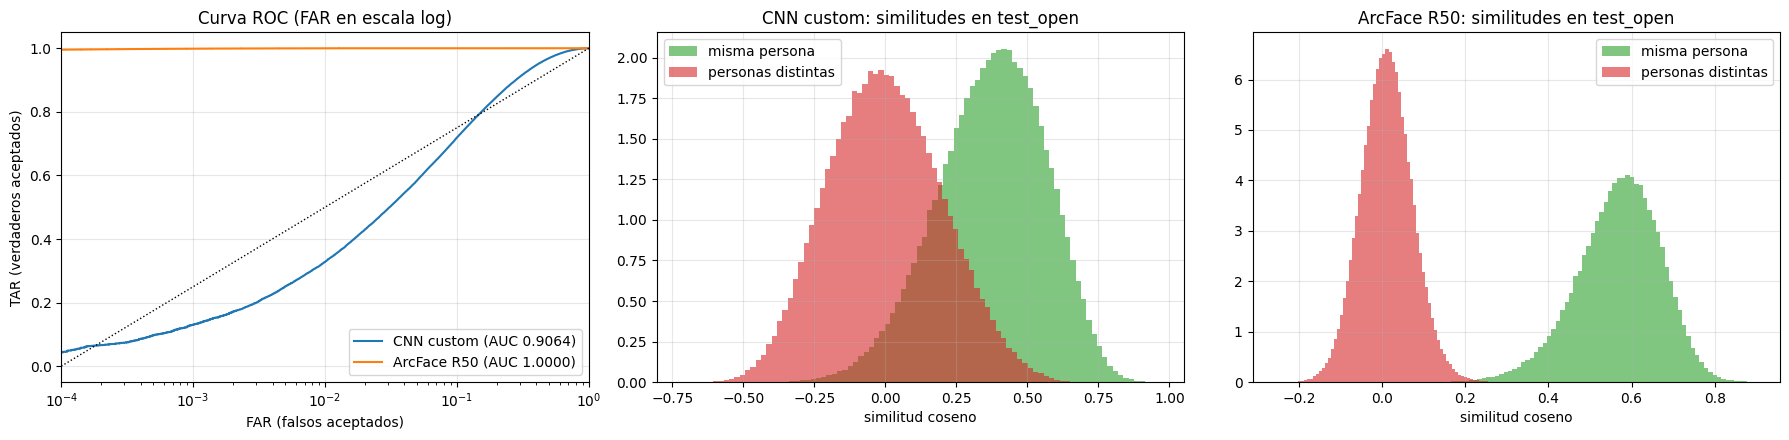

,AUC,EER,TAR@FAR=1e-2,TAR@FAR=1e-3
CNN custom,0.9064,0.1758,0.3280,0.1304
ArcFace R50,1.0000,0.0013,0.9998,0.9985


In [10]:
def balanced_pairs(ids, seed=SEED):
    iu = np.triu_indices(len(ids), 1)
    same = ids[iu[0]] == ids[iu[1]]
    pos = np.flatnonzero(same)
    neg = np.random.default_rng(seed).choice(np.flatnonzero(~same), size=len(pos), replace=False)
    sel = np.concatenate([pos, neg])
    return iu[0][sel], iu[1][sel], same[sel]


IDS = {s: splits[s].identity.to_numpy() for s in ["val_open", "test_open"]}
PAIRS = {s: balanced_pairs(IDS[s]) for s in IDS}
print({s: f"{p[2].sum()} positivos + {(~p[2]).sum()} negativos" for s, p in PAIRS.items()})


def scores_for(model, split):
    a, b, same = PAIRS[split]
    e = EMB[model][split]
    return (e[a] * e[b]).sum(1), same


def tar_at_far(same, scores, far):
    fpr, tpr, _ = roc_curve(same, scores)
    return float(np.interp(far, fpr, tpr))


verif = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for k, model in enumerate(MODEL_FILES):
    s, same = scores_for(model, "test_open")
    fpr, tpr, _ = roc_curve(same, s)
    e, _ = eer(same, s)
    verif[model] = {"AUC": roc_auc_score(same, s), "EER": e, "TAR@FAR=1e-2": tar_at_far(same, s, 1e-2),
                    "TAR@FAR=1e-3": tar_at_far(same, s, 1e-3)}
    axes[0].plot(fpr, tpr, label=f"{model} (AUC {verif[model]['AUC']:.4f})")
    axes[k + 1].hist(s[same], bins=80, alpha=0.6, density=True, label="misma persona", color="tab:green")
    axes[k + 1].hist(s[~same], bins=80, alpha=0.6, density=True, label="personas distintas", color="tab:red")
    axes[k + 1].set_title(f"{model}: similitudes en test_open")
    axes[k + 1].set_xlabel("similitud coseno")
    axes[k + 1].legend()
axes[0].set_xscale("log")
axes[0].set_xlim(1e-4, 1)
axes[0].plot([1e-4, 1], [1e-4, 1], "k:", lw=1)
axes[0].set_xlabel("FAR (falsos aceptados)")
axes[0].set_ylabel("TAR (verdaderos aceptados)")
axes[0].set_title("Curva ROC (FAR en escala log)")
axes[0].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(verif).T)

**Interpretación.** ArcFace separa casi perfectamente los pares de personas no vistas: **AUC 1.000, EER 0.13% y
TAR 99.9% a FAR = 1e-3**. En el histograma, las similitudes de la misma persona y las de personas distintas casi no se
tocan. La CNN custom logra un **AUC de 0.906**, que no es malo para un modelo entrenado desde cero con 75 personas, pero
sus dos distribuciones se superponen mucho: el EER es 17,6% y, si se exige aceptar solo 1 de cada 1.000 impostores,
reconoce apenas al 13% de los pares genuinos. Para una app de reconocimiento lo que importa es justamente la zona de FAR
bajo, y ahí la diferencia es enorme.

Un AUC de 1.000 hay que tomarlo con cuidado: no hay fuga entre splits, pero es probable que ArcFace ya conociera
a estas celebridades (ver la advertencia de la sección 2 y la sección 3.g).

### c) Elección del umbral (con `val_open`)

La app compara cada rostro contra **todos** los registros y devuelve la identidad del más parecido, o `unknown` si la
similitud máxima queda por debajo de `SIMILARITY_THRESHOLD`. Calibramos ese umbral **solo con `val_open`** (el test no
se toca) de dos formas:

1. **Verificación**: graficamos FAR y FRR en función del umbral y marcamos el punto **EER** y el de **FAR = 1e-3**.
2. **Identificación simulada como en la app**: en `val_open` registramos 7 personas con 5 fotos cada una (galería),
   dejamos 3 personas como desconocidas, y buscamos el umbral que **maximiza el F1 macro** (las 7 personas +
   `unknown`).

Nos quedamos con el umbral de (2), porque optimiza exactamente la decisión que toma la app, y lo comparamos con (1).

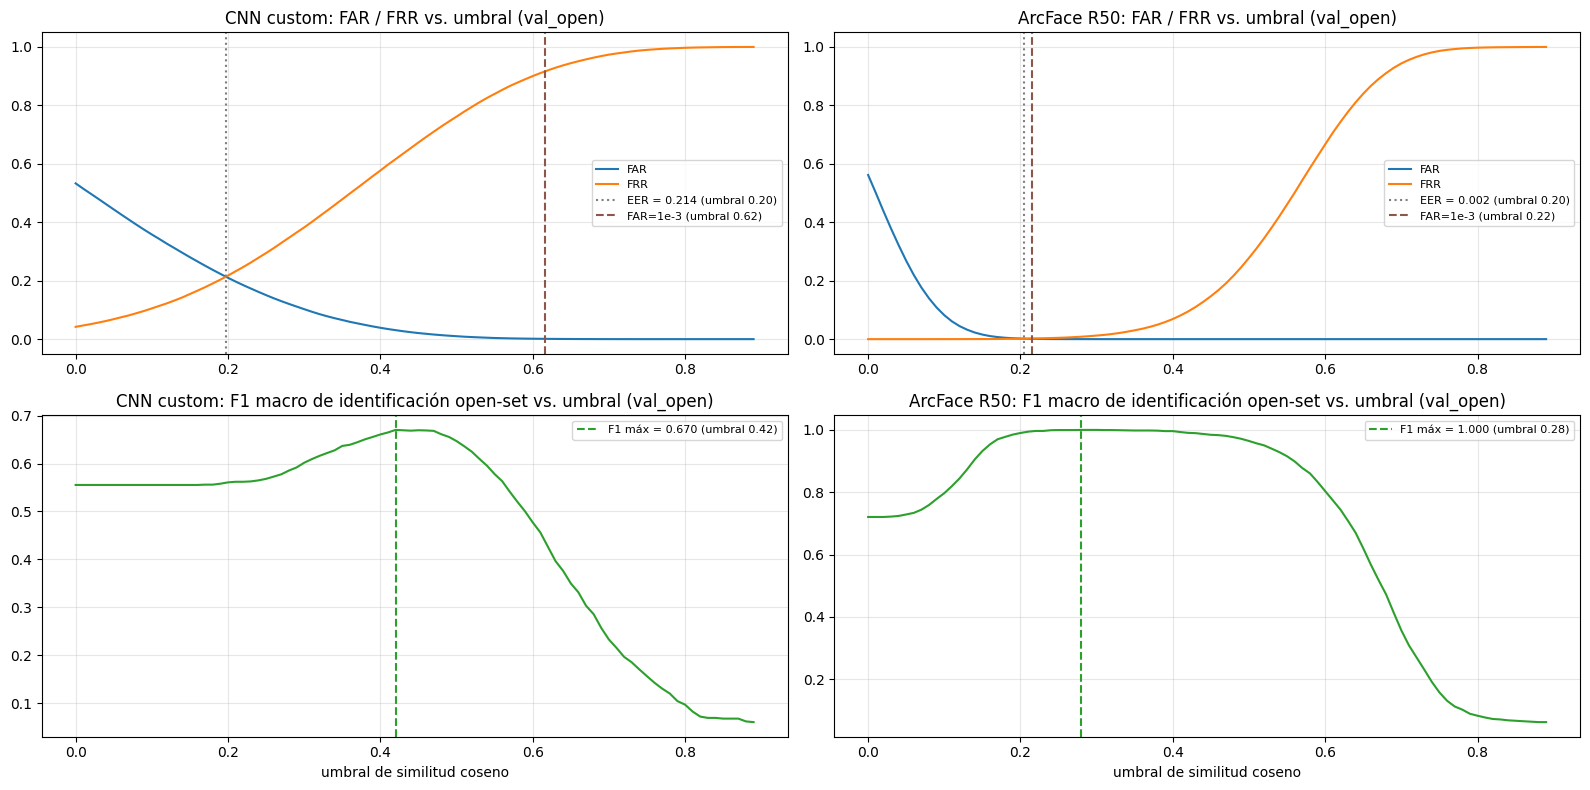

,umbral EER,umbral FAR=1e-3,umbral F1 máx (elegido),F1 macro val_open
CNN custom,0.1974,0.6165,0.42,0.6702
ArcFace R50,0.2041,0.2151,0.28,1.0000


In [11]:
GALLERY_PER_ID = 5


def make_gallery(split, n_known, seed=SEED, n_gallery=GALLERY_PER_ID):
    ids = IDS[split]
    names = np.array(sorted(set(ids)))
    rng = np.random.default_rng(seed)
    known = set(rng.choice(names, n_known, replace=False))
    gal, probe = [], []
    for n in names:
        idx = np.flatnonzero(ids == n)
        if n in known:
            g = rng.choice(idx, n_gallery, replace=False)
            gal += list(g)
            probe += list(np.setdiff1d(idx, g))
        else:
            probe += list(idx)
    return np.array(gal), np.array(probe), known


def identify(model, split, gal, probe):
    """Como FaceService.identify: máxima similitud contra cada embedding registrado."""
    e = EMB[model][split]
    S = e[probe] @ e[gal].T
    gal_ids = IDS[split][gal]
    names = np.array(sorted(set(gal_ids)))
    per_id = np.stack([S[:, gal_ids == n].max(1) for n in names], 1)
    return names, per_id


def open_set_predictions(names, per_id, thr):
    best = per_id.argmax(1)
    pred = names[best].astype(object)
    pred[per_id.max(1) < thr] = "unknown"
    return pred


from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

THRESHOLDS = np.round(np.arange(0.0, 0.9, 0.01), 2)
calib = {}
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for k, model in enumerate(MODEL_FILES):
    s, same = scores_for(model, "val_open")
    far = np.array([(s[~same] >= t).mean() for t in THRESHOLDS])
    frr = np.array([(s[same] < t).mean() for t in THRESHOLDS])
    e, thr_eer = eer(same, s)
    neg = np.sort(s[~same])
    thr_far3 = float(neg[int(np.ceil((1 - 1e-3) * len(neg))) - 1])

    gal, probe, known = make_gallery("val_open", n_known=7)
    names, per_id = identify(model, "val_open", gal, probe)
    truth = np.where(np.isin(IDS["val_open"][probe], list(known)), IDS["val_open"][probe], "unknown")
    f1s = np.array([f1_score(truth, open_set_predictions(names, per_id, t), average="macro") for t in THRESHOLDS])
    thr_f1 = float(THRESHOLDS[f1s.argmax()])
    calib[model] = {"umbral EER": float(thr_eer), "umbral FAR=1e-3": thr_far3, "umbral F1 máx (elegido)": thr_f1,
                    "F1 macro val_open": f1s.max()}

    ax = axes[0, k]
    ax.plot(THRESHOLDS, far, label="FAR")
    ax.plot(THRESHOLDS, frr, label="FRR")
    ax.axvline(thr_eer, color="tab:gray", ls=":", label=f"EER = {e:.3f} (umbral {thr_eer:.2f})")
    ax.axvline(thr_far3, color="tab:brown", ls="--", label=f"FAR=1e-3 (umbral {thr_far3:.2f})")
    ax.set_title(f"{model}: FAR / FRR vs. umbral (val_open)")
    ax.legend(fontsize=8)
    ax = axes[1, k]
    ax.plot(THRESHOLDS, f1s, color="tab:green")
    ax.axvline(thr_f1, color="tab:green", ls="--", label=f"F1 máx = {f1s.max():.3f} (umbral {thr_f1:.2f})")
    ax.set_title(f"{model}: F1 macro de identificación open-set vs. umbral (val_open)")
    ax.set_xlabel("umbral de similitud coseno")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
calib_df = pd.DataFrame(calib).T
display(calib_df)
THR = {m: calib[m]["umbral F1 máx (elegido)"] for m in MODEL_FILES}

**Interpretación y umbral elegido.**

- **ArcFace**: el F1 macro de identificación es ≈1.0 en toda una meseta de umbrales (≈0.22 a ≈0.38) y su máximo está en
  **0.28**, cerca del centro de esa meseta. Ese valor queda por encima del umbral EER (0.20) y del de FAR = 1e-3 (0.22),
  o sea que es **más conservador** que ambos: prefiere decir `unknown` antes que confundir a una persona con otra. Es
  el umbral que configuramos en la app: **`SIMILARITY_THRESHOLD=0.28`** (métrica coseno).
- **CNN custom**: el F1 tiene un pico (0.67) en 0.42. Por debajo acepta desconocidos como registrados; por encima
  empieza a rechazar a los registrados. El umbral de FAR = 1e-3 (0.62) rechazaría a casi todos los genuinos (FRR ≈90%):
  con este modelo no hay un umbral que sea a la vez seguro y útil.

Ambos umbrales se calibraron **solo con `val_open`**; las métricas de la sección siguiente se calculan en `test_open`
con esos umbrales fijos.

### b) Identificación: ¿quién es?

En `test_open` imitamos el uso de la app: **15 personas registradas** con 5 fotos cada una (como hacer `/insert` 5
veces) y **5 personas desconocidas** que nunca se registran. Todas las demás fotos son consultas (*probes*).

- **Top-1 / Top-5**: sobre las consultas de personas registradas, ¿la persona correcta es la más parecida (o está
  entre las 5 más parecidas)? No usa umbral.
- **Precision / Recall / F1 macro** sobre las 16 clases (15 personas + `unknown`), con el umbral calibrado en `val_open`.
- **Rechazo de desconocidos**: porcentaje de consultas de personas no registradas que el sistema devuelve como `unknown`.

In [12]:
gal, probe, known = make_gallery("test_open", n_known=15)
truth = np.where(np.isin(IDS["test_open"][probe], list(known)), IDS["test_open"][probe], "unknown")
print(f"Galería: {len(gal)} fotos de {len(known)} personas · consultas: {len(probe)} "
      f"({(truth != 'unknown').sum()} de registrados, {(truth == 'unknown').sum()} de desconocidos)")

ident = {}
preds = {}
for model in MODEL_FILES:
    names, per_id = identify(model, "test_open", gal, probe)
    kn = truth != "unknown"
    rank = np.argsort(-per_id[kn], 1)
    true_idx = np.searchsorted(names, truth[kn])
    pred = open_set_predictions(names, per_id, THR[model])
    preds[model] = pred
    p, r, f, _ = precision_recall_fscore_support(truth, pred, average="macro", zero_division=0)
    ident[model] = {
        "Top-1": (rank[:, 0] == true_idx).mean(),
        "Top-5": (rank[:, :5] == true_idx[:, None]).any(1).mean(),
        "precision macro": p,
        "recall macro": r,
        "F1 macro": f,
        "accuracy open-set": (pred == truth).mean(),
        "desconocidos rechazados": (pred[~kn] == "unknown").mean(),
        "registrados tomados como unknown": (pred[kn] == "unknown").mean(),
        "umbral": THR[model],
    }
display(pd.DataFrame(ident).T)

Galería: 75 fotos de 15 personas · consultas: 2979 (2204 de registrados, 775 de desconocidos)


,Top-1,Top-5,precision macro,recall macro,F1 macro,accuracy open-set,desconocidos rechazados,registrados tomados como unknown,umbral
CNN custom,0.7355,0.9769,0.6009,0.6718,0.6187,0.5589,0.1768,0.0998,0.42
ArcFace R50,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.28


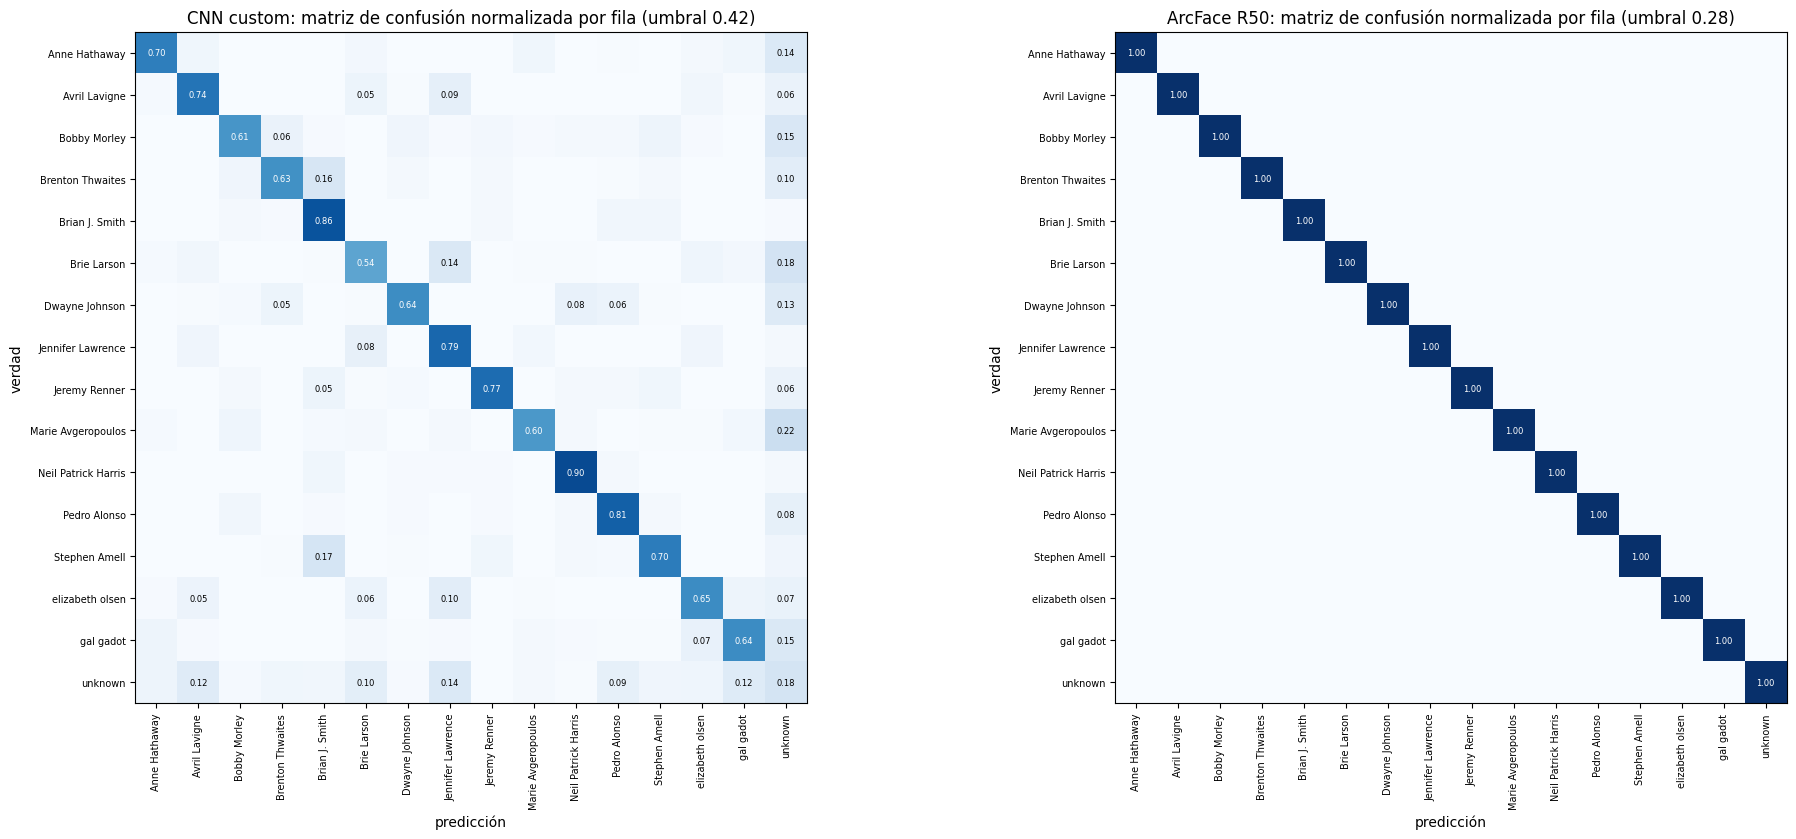

CNN custom — confusiones más frecuentes: unknown → Jennifer Lawrence (107), unknown → gal gadot (95), unknown → Avril Lavigne (93), unknown → Brie Larson (78), unknown → Pedro Alonso (66)
ArcFace R50 — confusiones más frecuentes: 


In [13]:
labels_cm = sorted(known) + ["unknown"]
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
for ax, model in zip(axes, MODEL_FILES):
    cm = confusion_matrix(truth, preds[model], labels=labels_cm, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels_cm)))
    ax.set_xticklabels(labels_cm, rotation=90, fontsize=7)
    ax.set_yticks(range(len(labels_cm)))
    ax.set_yticklabels(labels_cm, fontsize=7)
    for i in range(len(labels_cm)):
        for j in range(len(labels_cm)):
            if cm[i, j] >= 0.05:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xlabel("predicción")
    ax.set_ylabel("verdad")
    ax.set_title(f"{model}: matriz de confusión normalizada por fila (umbral {THR[model]:.2f})")
    ax.grid(False)
plt.tight_layout()
plt.show()

for model in MODEL_FILES:
    conf = pd.Series([f"{t} → {p}" for t, p in zip(truth, preds[model]) if t != p]).value_counts().head(5)
    print(f"{model} — confusiones más frecuentes:", ", ".join(f"{k} ({v})" for k, v in conf.items()))

**Interpretación.**

- **ArcFace** acierta el **100%** de las consultas de personas registradas (Top-1 = 1.0), rechaza como `unknown` al
  **100%** de las 775 fotos de personas no registradas y no toma a ningún registrado por desconocido. La matriz de
  confusión es diagonal.
- **CNN custom**: Top-1 de **73,6%** (el 97,7% está en el Top-5), pero con el umbral solo rechaza al **18%** de los
  desconocidos: la mayoría de las fotos de personas no registradas termina asignada a alguien de la galería (las
  confusiones más frecuentes son `unknown → Jennifer Lawrence` y `unknown → Gal Gadot`). En una app real, eso
  significa "reconocer" a gente que nunca se registró.
- **La brecha closed-set / open-set** explica el resultado: con las 75 personas que vio, la CNN clasifica bien (**91,9%
  top-1 en `test_closed`**); con personas nuevas cae a 73,6% y no sabe decir "no conozco a esta persona". Aprendió a
  separar *sus* 75 identidades más que a construir un espacio de embeddings que generalice.
- **El 100% de ArcFace no es el rendimiento esperado en la app**: con 20 celebridades que probablemente ya vio y
  5 fotos de galería, el problema es muy fácil para este modelo. En la sección 3.g lo probamos con un protocolo más
  exigente y con fotos nuestras.

### d) Clustering de los embeddings de test

Proyectamos con t-SNE los embeddings de `test_open` de cada modelo, lado a lado, y cuantificamos la separación con
silhouette (usando las identidades reales) y ARI / NMI de K-Means con k = 20.

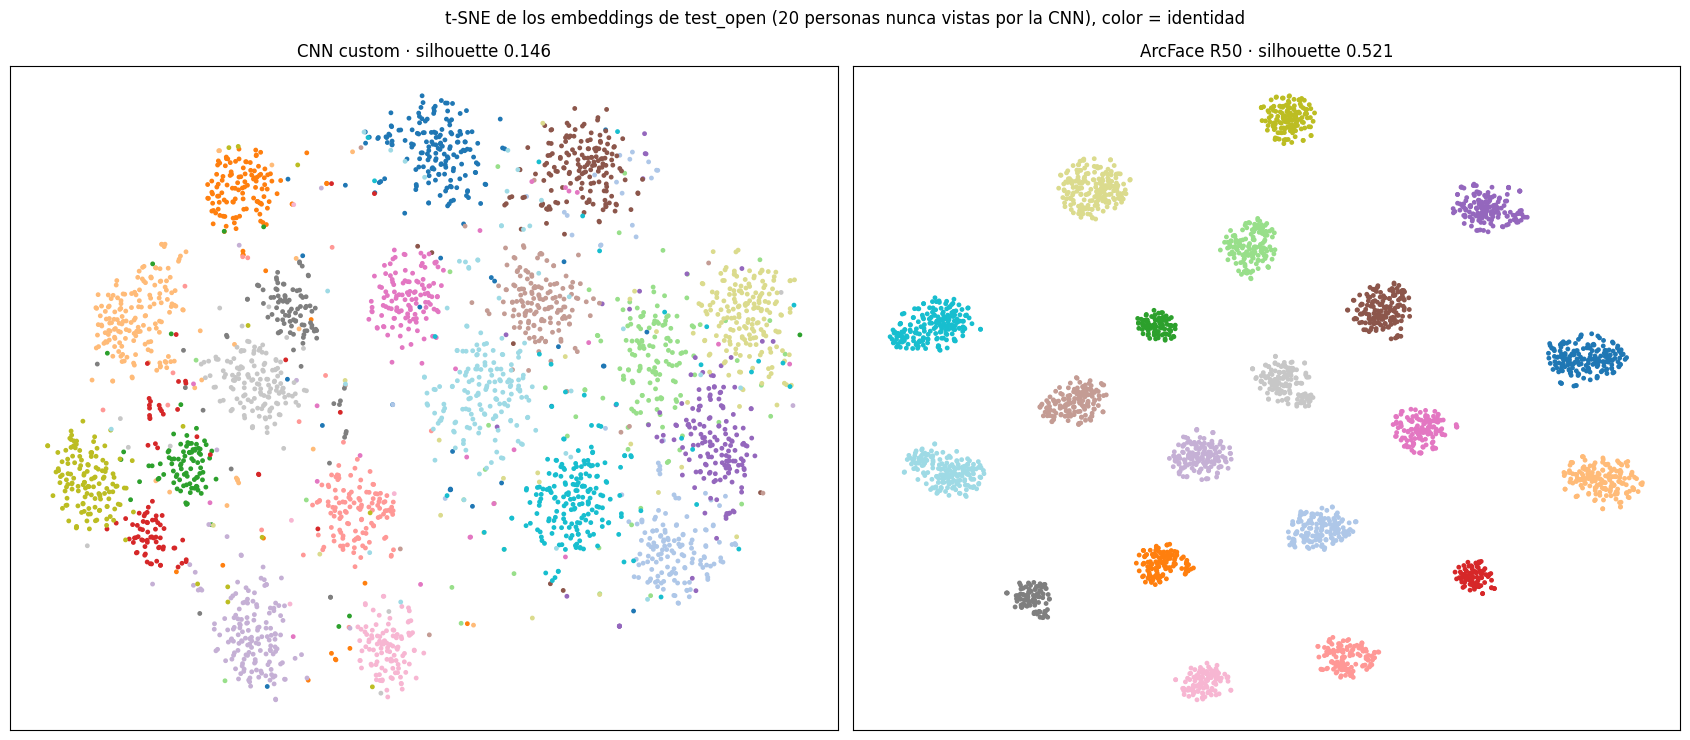

,silhouette (etiquetas reales),ARI K-Means,NMI K-Means
CNN custom,0.1461,0.6785,0.7572
ArcFace R50,0.5209,1.0000,1.0000


In [14]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

y_test = pd.factorize(IDS["test_open"])[0]
clust = {}
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, model in zip(axes, MODEL_FILES):
    e = EMB[model]["test_open"]
    km = KMeans(n_clusters=20, n_init=10, random_state=SEED).fit_predict(e)
    clust[model] = {"silhouette (etiquetas reales)": silhouette_score(e, y_test, metric="cosine"),
                    "ARI K-Means": adjusted_rand_score(y_test, km), "NMI K-Means": normalized_mutual_info_score(y_test, km)}
    Z = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(e)
    ax.scatter(Z[:, 0], Z[:, 1], c=y_test, cmap="tab20", s=6)
    ax.set_title(f"{model} · silhouette {clust[model]['silhouette (etiquetas reales)']:.3f}")
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("t-SNE de los embeddings de test_open (20 personas nunca vistas por la CNN), color = identidad")
plt.tight_layout()
plt.show()
display(pd.DataFrame(clust).T)

**Interpretación.** En el t-SNE de ArcFace cada una de las 20 personas forma una isla compacta y separada (silhouette
0.52, y K-Means recupera exactamente las identidades: ARI = NMI = 1.0). En el de la CNN custom se ven tendencias por
persona, pero los grupos se mezclan (silhouette 0.15, ARI 0.68). Es la misma conclusión de la verificación, vista de
forma geométrica: el embedding de la CNN agrupa a la gente nueva solo parcialmente.

### e) Análisis de errores

Con el umbral elegido de cada modelo, mostramos los **falsos positivos** (personas distintas aceptadas como la misma)
y **falsos negativos** (misma persona rechazada) con mayor error, sobre los pares de verificación de `test_open`.

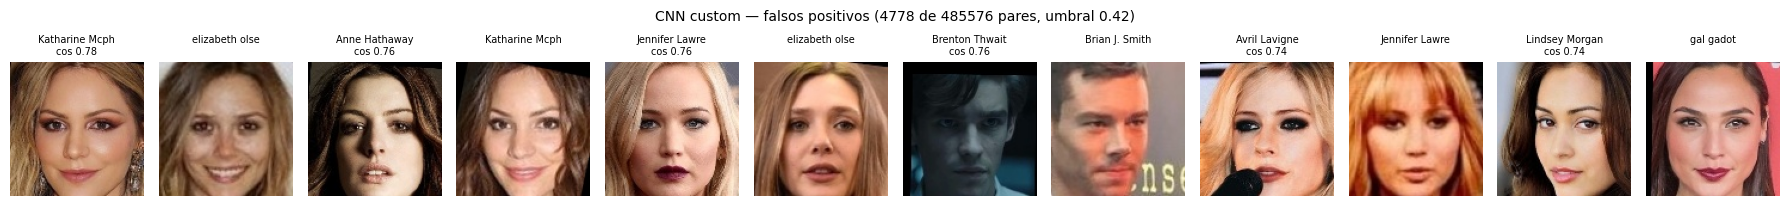

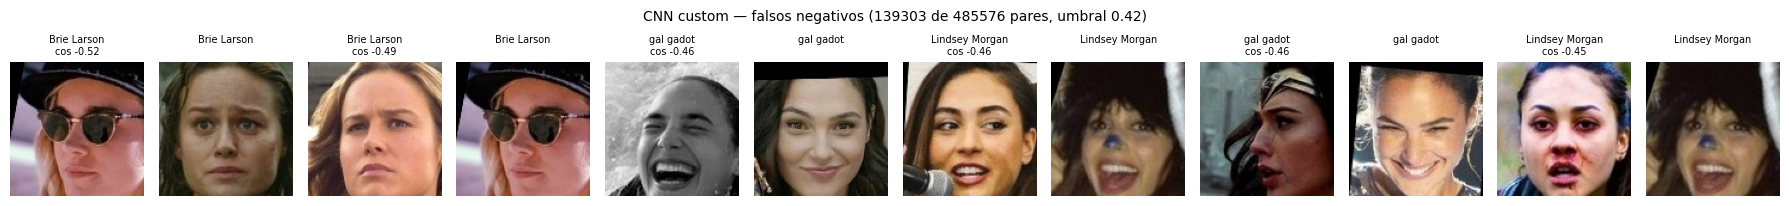

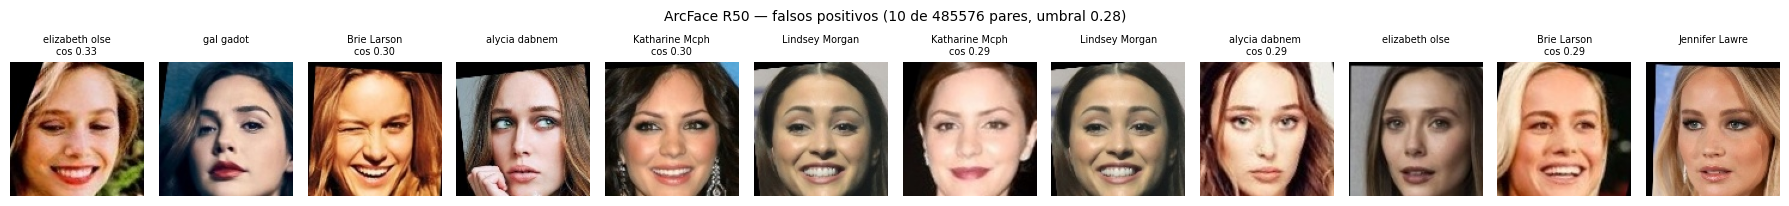

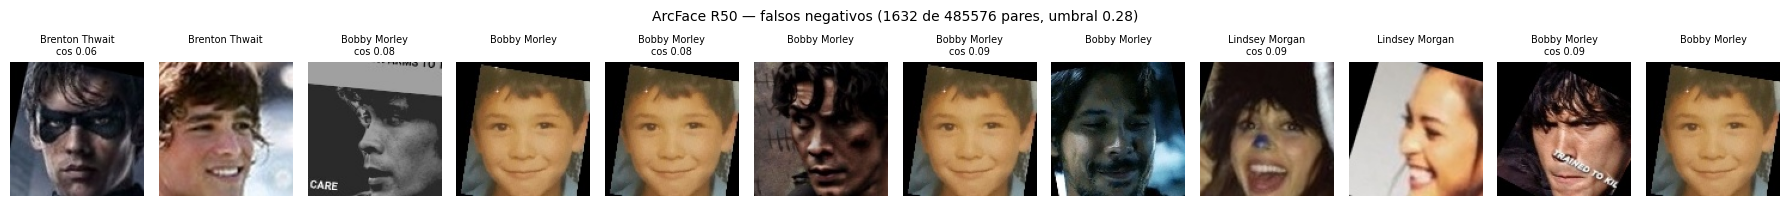

In [15]:
def show_pairs(model, kind, n=6):
    a, b, same = PAIRS["test_open"]
    s, _ = scores_for(model, "test_open")
    if kind == "FP":
        cand = np.flatnonzero(~same & (s >= THR[model]))
        cand = cand[np.argsort(-s[cand])][:n]
    else:
        cand = np.flatnonzero(same & (s < THR[model]))
        cand = cand[np.argsort(s[cand])][:n]
    total = (~same & (s >= THR[model])).sum() if kind == "FP" else (same & (s < THR[model])).sum()
    if len(cand) == 0:
        print(f"{model}: no hay {kind} con el umbral {THR[model]:.2f}")
        return
    fig, axes = plt.subplots(1, 2 * len(cand), figsize=(2 * len(cand) * 1.5, 2.2))
    for j, c in enumerate(cand):
        for k, idx in enumerate([a[c], b[c]]):
            ax = axes[2 * j + k]
            ax.imshow(cv2.cvtColor(faces["test_open"][idx], cv2.COLOR_BGR2RGB))
            ax.set_title(f"{IDS['test_open'][idx][:14]}" + (f"\ncos {s[c]:.2f}" if k == 0 else "\n"), fontsize=7)
            ax.axis("off")
    plt.suptitle(f"{model} — {'falsos positivos' if kind == 'FP' else 'falsos negativos'} "
                 f"({total} de {len(s)} pares, umbral {THR[model]:.2f})", fontsize=10)
    plt.tight_layout()
    plt.show()


for model in MODEL_FILES:
    show_pairs(model, "FP")
    show_pairs(model, "FN")

**Interpretación.**

- **Falsos positivos de ArcFace (solo 10 de ~486.000 pares)**: son todos entre mujeres jóvenes, de piel clara, con
  peinados y maquillaje similares (Elizabeth Olsen, Brie Larson, Katharine McPhee, Lindsey Morgan), con scores apenas por
  encima del umbral (0.29–0.33). Es el error esperable por **parecido real**, y refleja el sesgo del dataset (muchas
  personas de ese perfil). Los de la CNN son muchos más (4.778) y con scores altos (0.74–0.78).
- **Falsos negativos de ArcFace** (similitud ≈0.1): una foto con **máscara** (Brenton Thwaites como Robin), **fotos de
  infancia** comparadas con fotos de adulto (Bobby Morley), **perfiles**, fotos con texto encima y una cara pintada. Son
  los factores que ya identificamos en la notebook 1 (pose, oclusión, edad), que la alineación no puede compensar.
- **Hipótesis de causa**: para ArcFace, parecido real y condiciones extremas de captura; para la CNN, además, falta de
  capacidad y de datos para aprender rasgos que distingan a personas que no vio.

### f) Costo computacional

Medimos sobre **CPU** con `onnxruntime` (como corre el backend), un rostro por vez (como en una request), con 20
corridas de calentamiento y 200 medidas.

In [16]:
cost = {}
x1 = fp.to_model_input(faces["test_open"][0])
for model, path in MODEL_FILES.items():
    sess = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
    name = sess.get_inputs()[0].name
    for _ in range(20):
        sess.run(None, {name: x1})
    ts = []
    for _ in range(200):
        t0 = time.perf_counter()
        sess.run(None, {name: x1})
        ts.append(time.perf_counter() - t0)
    import onnx

    params = sum(int(np.prod(t.dims)) for t in onnx.load(str(path)).graph.initializer)
    cost[model] = {"tamaño (MB)": path.stat().st_size / 1e6, "parámetros (M)": params / 1e6,
                   "ms / rostro CPU (mediana)": 1000 * np.median(ts), "ms / rostro CPU (p95)": 1000 * np.percentile(ts, 95),
                   "dimensión embedding": sess.get_outputs()[0].shape[-1]}
display(pd.DataFrame(cost).T)

,tamaño (MB),parámetros (M),ms / rostro CPU (mediana),ms / rostro CPU (p95),dimensión embedding
CNN custom,11.7708,2.9396,3.2791,10.4746,512.0
ArcFace R50,174.3839,43.5910,27.4122,50.4056,512.0


### g) ¿Por qué ArcFace da 1.0? Sesgos de la evaluación y prueba con fotos propias

Que ArcFace saque **AUC 1.000, Top-1 100% y F1 1.000** no se explica por una fuga entre splits: la notebook 1 (sección
7.1) verifica que ningún archivo esté en dos splits, que las identidades de `val_open` / `test_open` no estén en train y
que ninguna imagen de val/test sea casi-duplicado de una de train. Además, la CNN, que es la que se entrenó con train,
da 0.906 de AUC: si hubiera fotos de test en train, sería la primera en dar 1.0.

Hay, en cambio, tres razones por las que **las métricas de ArcFace en `test_open` están infladas**:

1. **Las identidades probablemente no son nuevas para ArcFace.** `w600k_r50.onnx` se entrenó con WebFace600K,
   armado con fotos de celebridades de internet. Pins también son celebridades, así que es muy probable que varias de
   las 20 personas de `test_open` (y quizás algunas de estas mismas fotos) estuvieran en su entrenamiento. Para la CNN
   son personas no vistas; para ArcFace, probablemente no.
2. **Evaluación circular.** La limpieza de la notebook 1 usó embeddings de **ArcFace** (R7, R8 y R9), y se aplicó a
   todas las identidades **antes** de partir. R9 descarta justamente las imágenes que ArcFace deja lejos de su propia
   identidad o más cerca de otra, es decir, los casos donde ArcFace fallaría. Es un sesgo de selección a favor del
   modelo que después evaluamos.
3. **El protocolo es fácil**: 20 personas, 5 fotos de galería por persona y fotos de celebridades bien producidas.

Lo medimos en tres pasos:
- **g.1** Volvemos a agregar al test las imágenes que descartó R9 y vemos cuánto cambian las métricas.
- **g.2** Endurecemos el protocolo: todos los pares negativos, FAR más bajos (1e-4, 1e-5) y galerías de 1, 3 y 5
  fotos, con 10 sorteos de galería.
- **g.3** Probamos con **fotos nuestras**, que seguro no están en WebFace ni en Pins: es el escenario real de la app.

#### g.1 Test sin el filtro de ArcFace (R9)

La notebook 1 guarda las imágenes descartadas en `data/splits/discarded.csv` (si no existe, hay que volver a correr la
notebook 1: con las detecciones y los embeddings en caché tarda pocos minutos). Tomamos las descartadas por R9 que
son de personas de `test_open` y las sumamos al test: a la verificación como imágenes más, y a la identificación como
consultas, con **la misma galería** de la sección b.

Ojo al leer el resultado: algunas de esas imágenes son **etiquetas realmente erróneas** (por ejemplo, otra persona en
la carpeta). Que un modelo "falle" en ellas es correcto. Por eso las mostramos: la caída de las métricas es una cota
superior del efecto del sesgo, no el error real.

In [ ]:
def verif_all_pairs(emb, ids, fars=(1e-3, 1e-4, 1e-5)):
    # Verificación con TODOS los pares (sin muestrear negativos), para poder medir FAR bajos.
    s, same = pair_scores(emb, ids)
    e, _ = eer(same, s)
    out = {"pares +": int(same.sum()), "pares −": int((~same).sum()), "AUC": roc_auc_score(same, s), "EER": e}
    for far in fars:
        out[f"TAR@FAR={far:.0e}"] = tar_at_far(same, s, far)
    return out


def ident_metrics(names, per_id, truth, thr):
    kn = truth != "unknown"
    rank = np.argsort(-per_id[kn], 1)
    true_idx = np.searchsorted(names, truth[kn])
    pred = open_set_predictions(names, per_id, thr)
    p, r, f, _ = precision_recall_fscore_support(truth, pred, average="macro", zero_division=0)
    return {"Top-1": (rank[:, 0] == true_idx).mean(), "Top-5": (rank[:, :5] == true_idx[:, None]).any(1).mean(),
            "precision macro": p, "recall macro": r, "F1 macro": f,
            "desconocidos rechazados": (pred[~kn] == "unknown").mean() if (~kn).any() else np.nan,
            "registrados tomados como unknown": (pred[kn] == "unknown").mean()}


DISCARDED_CSV = SPLITS_DIR / "discarded.csv"
if not DISCARDED_CSV.exists():
    print(f"No existe {DISCARDED_CSV.relative_to(ROOT)}: correr la notebook 1 hasta la sección 7 y volver a esta celda.")
else:
    disc = pd.read_csv(DISCARDED_CSV)
    r9 = disc[disc.discard.str.startswith("R9") & disc.identity.isin(set(IDS["test_open"]))].reset_index(drop=True)
    print(f"Imágenes de personas de test_open descartadas por R9: {len(r9)} (de {disc.discard.str.startswith('R9').sum()} en total)")

    if len(r9):
        faces["test_open_r9"] = np.concatenate([faces["test_open"], load_faces(r9.aligned_path)])
        IDS["test_open_r9"] = np.concatenate([IDS["test_open"], r9.identity.to_numpy()])
        for model, sess in sessions.items():
            EMB[model]["test_open_r9"] = np.concatenate([EMB[model]["test_open"], embed_onnx(sess, faces["test_open_r9"][len(IDS["test_open"]):])])

        # Misma galería y mismas consultas que en la sección b; las imágenes de R9 se suman como consultas.
        gal, probe, known = make_gallery("test_open", n_known=15)
        r9_idx = np.arange(len(IDS["test_open"]), len(IDS["test_open_r9"]))
        rows = []
        for split, prb in [("test_open", probe), ("test_open_r9", np.concatenate([probe, r9_idx]))]:
            ids = IDS[split]
            truth = np.where(np.isin(ids[prb], list(known)), ids[prb], "unknown")
            for model in MODEL_FILES:
                names, per_id = identify(model, split, gal, prb)
                rows.append({"test": "limpio" if split == "test_open" else "+ descartadas por R9", "modelo": model,
                             **verif_all_pairs(EMB[model][split], ids), **ident_metrics(names, per_id, truth, THR[model])})
        r9_table = pd.DataFrame(rows).set_index(["modelo", "test"]).sort_index()
        display(r9_table.drop(columns=["pares +", "pares −"]).style.format(precision=4))

        # Qué son esas imágenes y qué dice cada modelo de ellas.
        n_show = min(len(r9), 12)
        fig, axes = plt.subplots(1, n_show, figsize=(1.6 * n_show, 2.6), squeeze=False)
        for ax, j in zip(axes[0], r9_idx[:n_show]):
            same_id = IDS["test_open_r9"] == IDS["test_open_r9"][j]
            same_id[j] = False
            sims = {m: float((EMB[m]["test_open_r9"][same_id] @ EMB[m]["test_open_r9"][j]).mean()) for m in MODEL_FILES}
            ax.imshow(cv2.cvtColor(faces["test_open_r9"][j], cv2.COLOR_BGR2RGB))
            ax.set_title(f"{IDS['test_open_r9'][j][:14]}\n" + "\n".join(f"{m.split()[0]} {v:.2f}" for m, v in sims.items()), fontsize=6)
            ax.axis("off")
        plt.suptitle("Descartadas por R9 (similitud media con las demás fotos de su identidad)", fontsize=9)
        plt.tight_layout()
        plt.show()

**Cómo leer g.1.** Si las métricas de ArcFace casi no cambian, la limpieza con ArcFace no explica el 1.0 (R9 sacó muy
pocas imágenes). Si bajan, esa diferencia es lo que la limpieza circular le regalaba a ArcFace. Para la CNN es
esperable un cambio menor, porque R9 no se decidió con sus embeddings. En cualquier caso, lo correcto para un trabajo
futuro es limpiar los splits de evaluación con un modelo distinto del que se evalúa, o limpiar solo train.

> _Completar con los números al ejecutar._

#### g.2 Protocolo más exigente

- **Verificación con todos los pares** de `test_open` (≈4,4 millones de negativos en lugar de una muestra del tamaño
  de los positivos), para poder medir TAR a FAR = 1e-4 y 1e-5. En una app que compara contra muchos registros, el FAR
  que importa es mucho menor que 1e-3.
- **Identificación con galerías de 1, 3 y 5 fotos** por persona y **10 sorteos** distintos de galería y de personas
  registradas, para ver la variabilidad en lugar de un único número. Con 1 foto de galería es lo más parecido a
  registrar a alguien con un solo `/insert`.

In [ ]:
COUNT_FMT = {"pares +": "{:,.0f}", "pares −": "{:,.0f}", "pares genuinos": "{:,.0f}", "pares impostores": "{:,.0f}"}
verif_full = pd.DataFrame({m: verif_all_pairs(EMB[m]["test_open"], IDS["test_open"]) for m in MODEL_FILES}).T
display(verif_full.style.format({k: v for k, v in COUNT_FMT.items() if k in verif_full}, precision=4))

rows = []
for n_gal in [1, 3, 5]:
    for seed in range(10):
        gal, probe, known = make_gallery("test_open", n_known=15, seed=seed, n_gallery=n_gal)
        truth = np.where(np.isin(IDS["test_open"][probe], list(known)), IDS["test_open"][probe], "unknown")
        for model in MODEL_FILES:
            names, per_id = identify(model, "test_open", gal, probe)
            rows.append({"modelo": model, "fotos de galería": n_gal, "sorteo": seed,
                         **ident_metrics(names, per_id, truth, THR[model])})
hard = pd.DataFrame(rows)
cols = ["Top-1", "F1 macro", "desconocidos rechazados", "registrados tomados como unknown"]
hard_summary = hard.groupby(["modelo", "fotos de galería"])[cols].agg(["mean", "std", "min"])
display(hard_summary.style.format(precision=4))

fig, axes = plt.subplots(1, len(cols), figsize=(18, 3.6))
for ax, c in zip(axes, cols):
    for model in MODEL_FILES:
        g = hard[hard.modelo == model].groupby("fotos de galería")[c]
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=4, label=model)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("fotos de galería por persona")
    ax.set_xticks([1, 3, 5])
axes[0].legend(fontsize=8)
plt.suptitle("Identificación en test_open: media ± desvío en 10 sorteos de galería (umbral fijo calibrado en val_open)")
plt.tight_layout()
plt.show()

**Cómo leer g.2.** Con todos los pares y FAR = 1e-4 / 1e-5 aparecen los pocos impostores con score alto que el
muestreo balanceado no llegaba a ver, y con 1 foto de galería una sola foto mala (perfil, oscura) alcanza para que una
persona registrada no se reconozca. Si ArcFace sigue cerca de 1.0 acá, el resultado es sólido **para estas
celebridades**; lo que todavía no sabemos es si vale para gente que no está en WebFace, y eso es g.3.

> _Completar con los números al ejecutar._

#### g.3 Fotos propias (personas que seguro no están en WebFace ni en Pins)

Es la prueba más honesta del modelo para la app: nosotros no estamos en el entrenamiento de ArcFace ni en el dataset.

**Cómo armar el set** (no se sube al repositorio: `data/*` está en el `.gitignore`):

```
data/own/
├── facundo/   *.jpg
├── roberto/   *.jpg
└── <otra persona, con su consentimiento>/  *.jpg
```

- **15–30 fotos por persona**, de **días distintos**: con y sin anteojos, distinta luz (día, noche, interior), algún
  perfil suave, distintas expresiones, y algunas con la **webcam o el celular que se va a usar en la app**.
- Nada de ráfagas ni fotos casi iguales: inflan las métricas igual que los duplicados de Pins.
- Si se puede, sumar 1–3 personas más (familiares, amigos) **con su consentimiento**: sirven como desconocidos.
- Alcanza con **una sola persona y 2 fotos** (una para registrar y otra para consultar); con más fotos y más
  personas el resultado es más confiable. Una persona con **una sola foto** no se registra: se usa como
  **impostor** (por ejemplo, un familiar que se parece).
- Las **fotos grupales** (varias caras) van aparte, en `data/own_grupos/`: ahí se evalúa cada cara como hace
  `/predict` en la app.
- Para elegir qué fotos se usan **solo como consulta**, se nombran con el prefijo `test_` (por ejemplo
  `test_ojos_cerrados.jpg`): nunca entran a la galería. El resto se reparte al azar (semilla fija) entre galería y
  consulta, con hasta `OWN_GALLERY` fotos de galería por persona.

Pasamos las fotos por **el mismo pipeline que la app**: SCRFD con borde, alineación a 112×112 y el modelo en ONNX.

Medimos tres cosas con el umbral **ya fijado** en `val_open` (no se recalibra con nuestras fotos):
1. **Verificación**: pares de la misma persona entre nuestras fotos contra impostores (las demás personas propias y
   las 3.054 fotos de `test_open`).
2. **Identificación como en la app**: registramos a cada persona con `OWN_GALLERY` fotos junto a las 15 celebridades de
   la sección b, y consultamos con el resto de sus fotos (detalle foto por foto).
3. **Rechazo de un desconocido real**: para cada persona propia, la sacamos de la galería y la consultamos. Debería
   salir `unknown` y no confundirse con un compañero ni con una celebridad.

In [ ]:
OWN_DIR = ROOT / "data" / "own"
OWN_GALLERY = 2  # fotos con las que se registra cada persona (como hacer /insert); las demás son consultas
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

own_files = sorted(p for p in OWN_DIR.glob("*/*") if p.suffix.lower() in IMG_EXT) if OWN_DIR.exists() else []
OWN_AVAILABLE = len(own_files) >= 2
if not OWN_AVAILABLE:
    print(f"Para esta sección hacen falta al menos 2 fotos en {OWN_DIR.relative_to(ROOT)}/<persona>/ "
          "(ver instrucciones arriba). Se saltea g.3.")
else:
    detector = fp.load_detector(MODELS_DIR / "det_10g.onnx", META["det_input_size"], META["det_score_threshold"])
    own_rows, own_faces = [], []
    for p in tqdm(own_files, desc="detectando fotos propias"):
        img = cv2.imread(str(p))  # aplica la rotación EXIF de las fotos de celular
        dets = fp.detect(detector, img, pad=META["det_pad"]) if img is not None else []
        status = "ok" if dets else ("no se pudo leer" if img is None else "sin rostro")
        own_rows.append({"persona": p.parent.name, "archivo": p.name, "estado": status, "rostros": len(dets)})
        if dets:
            main = max(dets, key=lambda d: (d.box[2] - d.box[0]) * (d.box[3] - d.box[1]))
            own_faces.append(fp.align(img, main.kps, FACE_SIZE))
    own_log = pd.DataFrame(own_rows)
    display(own_log.groupby("persona").estado.value_counts().unstack(fill_value=0))
    own = own_log[own_log.estado == "ok"].reset_index(drop=True)
    # Las personas con una sola foto no se pueden registrar (hace falta una foto para la galería y otra para
    # consultar): se usan solo como impostores.
    single = sorted(n for n, k in own.persona.value_counts().items() if k < 2)
    if single:
        print("Con una sola foto (solo como impostores):", single)
    OWN_AVAILABLE = len(own) >= 2
    if not OWN_AVAILABLE:
        print("Hacen falta al menos 2 fotos con rostro. Se saltea g.3.")

if OWN_AVAILABLE:
    faces["own"] = np.stack(own_faces)
    IDS["own"] = own.persona.to_numpy()
    OWN_FORCED_TEST = own.archivo.str.lower().str.startswith("test_").to_numpy()  # nunca van a la galería
    for model, sess in sessions.items():
        EMB[model]["own"] = embed_onnx(sess, faces["own"])

    # Control visual de la alineación: si acá una cara sale torcida o cortada, el problema es la foto, no el modelo.
    show = np.concatenate([np.flatnonzero(IDS["own"] == n)[:8] for n in sorted(set(IDS["own"]))])
    ncols = 8
    nrows = int(np.ceil(len(show) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.5 * ncols, 1.7 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, j in zip(axes.ravel(), show):
        ax.imshow(cv2.cvtColor(faces["own"][j], cv2.COLOR_BGR2RGB))
        ax.set_title(IDS["own"][j], fontsize=7)
    plt.suptitle("Fotos propias alineadas (primeras 8 por persona)", fontsize=9)
    plt.tight_layout()
    plt.show()

In [ ]:
if OWN_AVAILABLE:
    # 1. Verificación: genuinos entre fotos propias; impostores = otras personas propias + todas las de test_open.
    own_verif, own_scores = {}, {}
    fig, axes = plt.subplots(1, len(MODEL_FILES), figsize=(16, 4))
    for ax, model in zip(axes, MODEL_FILES):
        e = EMB[model]["own"]
        s_own, same_own = pair_scores(e, IDS["own"])
        s_cel = (e @ EMB[model]["test_open"].T).ravel()
        gen = s_own[same_own]
        imp = np.concatenate([s_own[~same_own], s_cel])
        y = np.r_[np.ones(len(gen), bool), np.zeros(len(imp), bool)]
        s = np.r_[gen, imp]
        own_scores[model] = (gen, imp)
        own_verif[model] = {"pares genuinos": len(gen), "pares impostores": len(imp), "AUC": roc_auc_score(y, s),
                            "EER": eer(y, s)[0], "similitud genuina (mediana)": np.median(gen),
                            "similitud genuina (mín)": gen.min(), "impostor máx": imp.max(),
                            "FRR al umbral": (gen < THR[model]).mean(), "FAR al umbral": (imp >= THR[model]).mean(),
                            "umbral": THR[model]}
        bins = np.linspace(-0.3, 1, 80)
        ax.hist(gen, bins=bins, density=True, alpha=0.6, color="tab:green", label="misma persona (propias)")
        ax.hist(imp, bins=bins, density=True, alpha=0.6, color="tab:red", label="impostores (propias + test_open)")
        ax.axvline(THR[model], color="k", ls="--", label=f"umbral {THR[model]:.2f}")
        ax.set_title(f"{model}: similitudes con fotos propias")
        ax.set_xlabel("similitud coseno")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    own_verif_df = pd.DataFrame(own_verif).T
    display(own_verif_df.style.format({k: v for k, v in COUNT_FMT.items() if k in own_verif_df}, precision=4))

In [ ]:
if OWN_AVAILABLE:
    # 2 y 3. Identificación como en la app: base = 15 celebridades (5 fotos) + personas propias (OWN_GALLERY fotos).
    rng = np.random.default_rng(SEED)
    own_names = sorted(set(IDS["own"]))
    own_gal = {}
    for n in own_names:
        idx = np.flatnonzero(IDS["own"] == n)
        cand = idx[~OWN_FORCED_TEST[idx]]
        own_gal[n] = rng.choice(cand, min(OWN_GALLERY, len(cand), len(idx) - 1), replace=False)
    own_registrable = [n for n in own_names if len(own_gal[n])]
    print("Galería propia:", {n: list(own.archivo[own_gal[n]]) for n in own_names})
    cel_gal, _, cel_known = make_gallery("test_open", n_known=15)


    def app_search(model, probe_idx, registered):
        # Similitud máxima contra cada persona registrada (celebridades + las propias de `registered`).
        e = EMB[model]
        g_own = np.concatenate([own_gal[n] for n in registered]) if registered else np.array([], int)
        G = np.concatenate([e["test_open"][cel_gal], e["own"][g_own]])
        gid = np.concatenate([IDS["test_open"][cel_gal], IDS["own"][g_own]])
        S = e["own"][probe_idx] @ G.T
        names = np.array(sorted(set(gid)))
        per_id = np.stack([S[:, gid == n].max(1) for n in names], 1)
        return open_set_predictions(names, per_id, THR[model]), per_id.max(1)


    rows, detail = [], []
    for model in MODEL_FILES:
        # 2. Todas las personas propias registradas: se consulta con las fotos que no están en la galería.
        probe_idx = np.concatenate([np.setdiff1d(np.flatnonzero(IDS["own"] == n), own_gal[n]) for n in own_registrable])
        pred, best = app_search(model, probe_idx, own_registrable)
        truth = IDS["own"][probe_idx]
        for j, t, pr, b in zip(probe_idx, truth, pred, best):
            detail.append({"modelo": model, "persona": t, "foto consultada": own.archivo[j],
                           "similitud con su galería": float((EMB[model]["own"][own_gal[t]] @ EMB[model]["own"][j]).max()),
                           "similitud máx en la base": float(b), "predicción": pr, "acierta": pr == t})
        for n in own_registrable:
            m = truth == n
            rows.append({"modelo": model, "persona": n, "escenario": "registrada", "consultas": int(m.sum()),
                         "correcta": (pred[m] == n).mean(), "unknown": (pred[m] == "unknown").mean(),
                         "otra persona": ((pred[m] != n) & (pred[m] != "unknown")).mean()})
        # 3. Cada persona propia sin registrar (desconocido real): todas sus fotos son consultas.
        for n in own_names:
            idx = np.flatnonzero(IDS["own"] == n)
            pred, best = app_search(model, idx, [o for o in own_names if o != n])
            rows.append({"modelo": model, "persona": n, "escenario": "NO registrada", "consultas": len(idx),
                         "correcta": (pred == "unknown").mean(), "unknown": (pred == "unknown").mean(),
                         "otra persona": (pred != "unknown").mean(), "similitud máx (mediana)": np.median(best)})
    display(pd.DataFrame(detail).set_index(["modelo", "persona", "foto consultada"]).style.format(precision=3))
    own_ident = pd.DataFrame(rows).set_index(["modelo", "escenario", "persona"])
    display(own_ident.style.format(precision=3))
    print("En 'NO registrada', 'correcta' = la devolvió como unknown; 'otra persona' = la confundió con alguien de la base.")

#### g.4 Fotos grupales: cada cara por separado, como `/predict`

La app no se queda con una sola cara: en `/predict` detecta **todas** las caras de la foto y busca a cada una en la
base. Lo reproducimos con las fotos de `data/own_grupos/` y la misma base de la sección g.3 (15 celebridades + las
personas propias registradas). Se espera que cada persona registrada salga con su nombre y el resto como `unknown`.

In [ ]:
GROUP_DIR = ROOT / "data" / "own_grupos"
group_files = sorted(p for p in GROUP_DIR.glob("*") if p.suffix.lower() in IMG_EXT) if GROUP_DIR.exists() else []
if not (OWN_AVAILABLE and group_files):
    print(f"No hay fotos en {GROUP_DIR.relative_to(ROOT)} (o se salteó g.3). Se saltea g.4.")
else:
    group_rows = []
    model = "ArcFace R50"  # el modelo de la app; la CNN se puede ver cambiando esta línea
    e = EMB[model]
    g_own = np.concatenate([own_gal[n] for n in own_registrable])
    G = np.concatenate([e["test_open"][cel_gal], e["own"][g_own]])
    gid = np.concatenate([IDS["test_open"][cel_gal], IDS["own"][g_own]])
    names = np.array(sorted(set(gid)))
    fig, axes = plt.subplots(1, len(group_files), figsize=(4.5 * len(group_files), 5), squeeze=False)
    for ax, path in zip(axes[0], group_files):
        img = cv2.imread(str(path))
        dets = fp.detect(detector, img, pad=META["det_pad"])
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")
        if not dets:
            continue
        emb_faces = embed_onnx(sessions[model], [fp.align(img, d.kps, FACE_SIZE) for d in dets])
        S = emb_faces @ G.T
        per_id = np.stack([S[:, gid == n].max(1) for n in names], 1)
        pred = open_set_predictions(names, per_id, THR[model])
        for d, pr, s in zip(dets, pred, per_id.max(1)):
            x1, y1, x2, y2 = d.box
            color = "lime" if pr != "unknown" else "red"
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=color, lw=2))
            ax.text(x1, y1 - 5, f"{pr} {s:.2f}", color=color, fontsize=8, weight="bold")
            group_rows.append({"foto": path.name, "x": int(x1), "lado (px)": int(x2 - x1), "predicción": pr,
                               "similitud máx": float(s)})
    plt.suptitle(f"{model}: predicción por cara (umbral {THR[model]:.2f}); verde = persona registrada, rojo = unknown")
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(group_rows).set_index(["foto", "x"]).style.format(precision=3))

#### g.5 ¿Hay que subir el umbral? 0.28 vs. umbrales más altos

En las pruebas con fotos propias aparece un caso que `val_open` no tiene: un **hermano** (impostor real con parecido
familiar) queda por encima de 0.28. Medimos qué pasaría con umbrales más altos en los tres conjuntos: la
identificación open-set de `val_open` (donde se calibró), la de `test_open` y las consultas propias.

In [ ]:
cmp_thr = [0.28, 0.35, 0.40, 0.45, 0.50, 0.55]
model = "ArcFace R50"
rows = []
for thr in cmp_thr:
    row = {"umbral": thr}
    for split, n_known in [("val_open", 7), ("test_open", 15)]:
        gal, probe, known = make_gallery(split, n_known=n_known)
        truth = np.where(np.isin(IDS[split][probe], list(known)), IDS[split][probe], "unknown")
        names, per_id = identify(model, split, gal, probe)
        m = ident_metrics(names, per_id, truth, thr)
        row[f"F1 {split}"] = m["F1 macro"]
        row[f"registrados → unknown ({split})"] = m["registrados tomados como unknown"]
    if OWN_AVAILABLE:
        d = pd.DataFrame(detail)
        d = d[d.modelo == model]
        # El más parecido no depende del umbral: con uno más alto, una consulta acertada solo puede pasar a unknown.
        ok = (d["similitud máx en la base"] >= thr) & (d["predicción"] == d["persona"])
        row["fotos propias reconocidas"] = f"{int(ok.sum())}/{len(d)}"
        for n in own_names:
            idx = np.flatnonzero(IDS["own"] == n)
            _, best = app_search(model, idx, [o for o in own_names if o != n])
            row[f"{n} sin registrar aceptado"] = int((best >= thr).sum())
    rows.append(row)
display(pd.DataFrame(rows).set_index("umbral").style.format(precision=3))

**Interpretación de g.3–g.5 y decisión sobre el umbral.**

Valores de nuestra corrida con ArcFace (verificar al ejecutar; galería = 2 fotos `registro_*` por persona):

- **Personas comunes, no famosas**: nos reconoce a los dos en todas las consultas, incluso en casos difíciles: ojos
  cerrados (0.82), otro día y otra ropa (0.82), bigote (0.77), Roberto con anteojos frente al espejo (0.68), y en un
  aula con gente atrás (0.70). Las similitudes genuinas más bajas son las de **fotos de varios años antes**
  (Facundo a los 18 con pelo teñido: 0.55; Messi joven: 0.54) y las de **luz de boliche** (0.52–0.54).
- **Personas distintas sin parentesco** (nosotros dos, Messi, amigos y gente de fondo): nunca pasan de ≈0.13. No
  hay ninguna confusión entre ellas, ni en fotos individuales ni en las grupales de g.4.
- **El único error es el hermano de Facundo**, que no está registrado: su similitud con Facundo es 0.47, por encima
  de 0.28, así que la app lo toma por Facundo. Es el caso conocido de los **familiares cercanos** (y gemelos), que
  ningún conjunto de celebridades sin parentesco representa: en `val_open` el impostor típico ronda 0.02.

**Decisión: mantenemos `SIMILARITY_THRESHOLD = 0.28`.** El enunciado pide calibrar el umbral con datos de
validación y no a ojo, y 0.28 es el que sale de `val_open` (sección c). Un umbral de ≈0.5 corregiría el caso del
hermano, pero lo estaríamos eligiendo mirando las fotos de test, y la ventana que separa todo es muy angosta
(hermano 0.47 vs. Facundo en el boliche 0.52): con una sola foto del hermano no hay datos para calibrarlo. Lo dejamos
documentado como **limitación conocida**: para un uso con familiares en la base habría que recalibrar con un set de
validación que incluya parientes, o pedir más fotos de registro por persona.


## 4. Comparación y elección final

In [17]:
comparison = pd.concat(
    [pd.DataFrame(verif), pd.DataFrame(ident).loc[["Top-1", "Top-5", "precision macro", "recall macro", "F1 macro",
                                                   "desconocidos rechazados", "umbral"]],
     pd.DataFrame(clust), pd.DataFrame(cost)]
)
comparison.to_csv(RESULTS_DIR / "comparison.csv")
display(comparison.style.format(precision=4))

,CNN custom,ArcFace R50
AUC,0.9064,1.0000
EER,0.1758,0.0013
TAR@FAR=1e-2,0.3280,0.9998
TAR@FAR=1e-3,0.1304,0.9985
Top-1,0.7355,1.0000
Top-5,0.9769,1.0000
precision macro,0.6009,1.0000
recall macro,0.6718,1.0000
F1 macro,0.6187,1.0000
desconocidos rechazados,0.1768,1.0000


### Conclusión: elegimos **ArcFace R50** (`w600k_r50.onnx`) para la app

| Criterio | CNN custom | ArcFace R50 |
|---|---|---|
| Desempeño (personas no vistas) | AUC 0.906 · Top-1 74% · rechaza 18% de desconocidos | AUC 1.000 · Top-1 100% · rechaza 100% |
| Costo | **11,8 MB · 2,9 M parámetros · 3,3 ms por rostro en CPU** | 174 MB · 43,6 M parámetros · 27 ms por rostro |
| Licencia | propia (sin restricciones) | InsightFace: solo uso no comercial / investigación (un TP entra) |
| Integración | ONNX exportado, misma entrada | ONNX listo, mismo detector y alineación que usamos |

**Por qué la CNN custom rinde menos.** No es un problema de implementación: aprende bien la tarea con la que la
entrenamos (92% de accuracy con las 75 personas que vio), y su AUC de 0.906 con gente nueva muestra que el embedding
generaliza en parte. La diferencia se explica por:

1. **Datos**: ~9.100 fotos de 75 personas, contra un modelo entrenado sobre **WebFace600K**, órdenes de magnitud más
   personas y fotos. Con 75 identidades el modelo ve muy pocas formas distintas de "ser otra persona", que es justo lo que
   necesita para separar a gente nueva.
2. **Capacidad**: 2,9 M de parámetros contra 43,6 M (15 veces más).
3. **Entrenamiento**: 15 épocas (unos 5 min) en una GTX 1650. Las curvas de E4 y E5 seguían subiendo cuando se cortaron.
4. **Métricas de ArcFace infladas en `test_open`**: es probable que nuestras celebridades estén en WebFace, y la limpieza
   del dataset se hizo con el propio ArcFace. Por eso su 1.0 no es el rendimiento esperado con gente común; la sección
   3.g mide ese efecto y lo prueba con fotos nuestras. Aun así, el margen sobre la CNN es tan grande que no cambia la
   elección.

La CNN tiene a favor el tamaño y la velocidad (15 veces más chica y 8 veces más rápida). Pero en una app de
reconocimiento rechazar desconocidos es esencial (si no, el sistema "reconoce" a cualquiera), y ahí la CNN no es usable
(18% de rechazo). **Elegimos ArcFace R50**, con `SIMILARITY_THRESHOLD = 0.28` (coseno). Para mejorar la CNN, el camino
sería más identidades (aunque sean menos fotos por persona), más épocas con margen angular, o *fine-tuning* de un
backbone preentrenado.

## 5. Exportación del modelo

El modelo elegido es **`w600k_r50.onnx`** (reconocedor) junto con **`det_10g.onnx`** (detector), ambos del paquete
`buffalo_l` de InsightFace. Ya vienen en ONNX, así que el backend los carga con `onnxruntime` sin depender de código de
PyTorch. No se suben al repositorio (`*.onnx` está en el `.gitignore`).

- **Link público de solo lectura** (release oficial de InsightFace):
  https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip
- Descomprimir y copiar `w600k_r50.onnx` y `det_10g.onnx` en `models/`.
- La CNN custom también quedó exportada (`models/custom_cnn.onnx`, verificada contra PyTorch); se podría usar cambiando
  `MODEL_NAME` y el umbral.

Configuración resultante para los `.env` de la app:

In [18]:
chosen = "ArcFace R50"
config = {
    "MODEL_NAME": MODEL_FILES[chosen].name,
    "DETECTOR_MODEL_NAME": "det_10g.onnx",
    "EMBEDDING_DIM": int(cost[chosen]["dimensión embedding"]),
    "FACE_SIZE": FACE_SIZE,
    "SIMILARITY_METRIC": "cosine",
    "SIMILARITY_THRESHOLD": THR[chosen],
}
(RESULTS_DIR / "app_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(json.dumps(config, indent=2))

{
  "MODEL_NAME": "w600k_r50.onnx",
  "DETECTOR_MODEL_NAME": "det_10g.onnx",
  "EMBEDDING_DIM": 512,
  "FACE_SIZE": 112,
  "SIMILARITY_METRIC": "cosine",
  "SIMILARITY_THRESHOLD": 0.28
}
